In [1]:
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd



In [2]:
RE = 120
CA = 0.01
BETA = 45
TIME_TARGET = 1800.0

QUANTITIES = [
    "h",
    "delta_M_ML",
    "delta_Tw_ML",
    "delta_Dx_ML",
    "delta_Px_ML",
]

PLOT_LABELS = {
    "h": r"$h$",
    "q": r"$q$",
    "delta_M_ML": r"$ \Delta \mathcal{M}_{\mathrm{ML}} $",
    "delta_Tw_ML": r"$\Delta \mathcal{T}_{w,\mathrm{ML}}$",
    "delta_Dx_ML": r"$\Delta \mathcal{D}_{x,\mathrm{ML}}$",
    "delta_Px_ML": r"$\Delta \mathcal{P}_{x,\mathrm{ML}}$",
}

DATA_DIR = Path(
    "/blue/bala1s/krishnap.kalivel/"
    "TLFHydrodynamics/thinfilm-closure-ml/"
    "datasets/BasC/param_space/ClosureData"
)

re_tag = f"{RE:03d}"
ca_tag = f"{CA:.3f}".replace(".", "_")
beta_tag = f"{BETA:g}".replace(".", "_")

filepath = DATA_DIR / (
    f"thinfilm_closure_data_Re{re_tag}_"
    f"Ca{ca_tag}_theta{beta_tag}.h5"
)

if not filepath.is_file():
    raise FileNotFoundError(filepath)

with h5py.File(filepath, "r") as f:
    x = np.asarray(f["x"][:]).reshape(-1)
    t = np.asarray(f["t"][:]).reshape(-1)

    if not t.min() <= TIME_TARGET <= t.max():
        raise ValueError(
            f"Requested time is outside [{t.min():g}, {t.max():g}]."
        )

    it = int(np.argmin(np.abs(t - TIME_TARGET)))
    selected_time = t[it]
    previous_time = np.asarray(f["tm"][:]).reshape(-1)[it]

    profiles = {}

    for name in QUANTITIES:
        if name not in f:
            raise KeyError(f"Dataset not found: {name}")

        dataset = f[name]

        # Slice the HDF5 dataset BEFORE converting to NumPy.
        if dataset.shape == (x.size, t.size):
            profiles[name] = np.asarray(dataset[:, it])
        elif dataset.shape == (t.size, x.size):
            profiles[name] = np.asarray(dataset[it, :])
        else:
            raise ValueError(
                f"{name}: unexpected shape {dataset.shape}"
            )
            
        
profiles["delta_M_ML_x"] = np.gradient(profiles["delta_M_ML"], x, edge_order=2)
print(f"Loaded: {filepath.name}")

print(f"Requested time: {TIME_TARGET:g}")
print(f"Selected time:  {selected_time:g}")

Loaded: thinfilm_closure_data_Re120_Ca0_010_theta45.h5
Requested time: 1800
Selected time:  1800


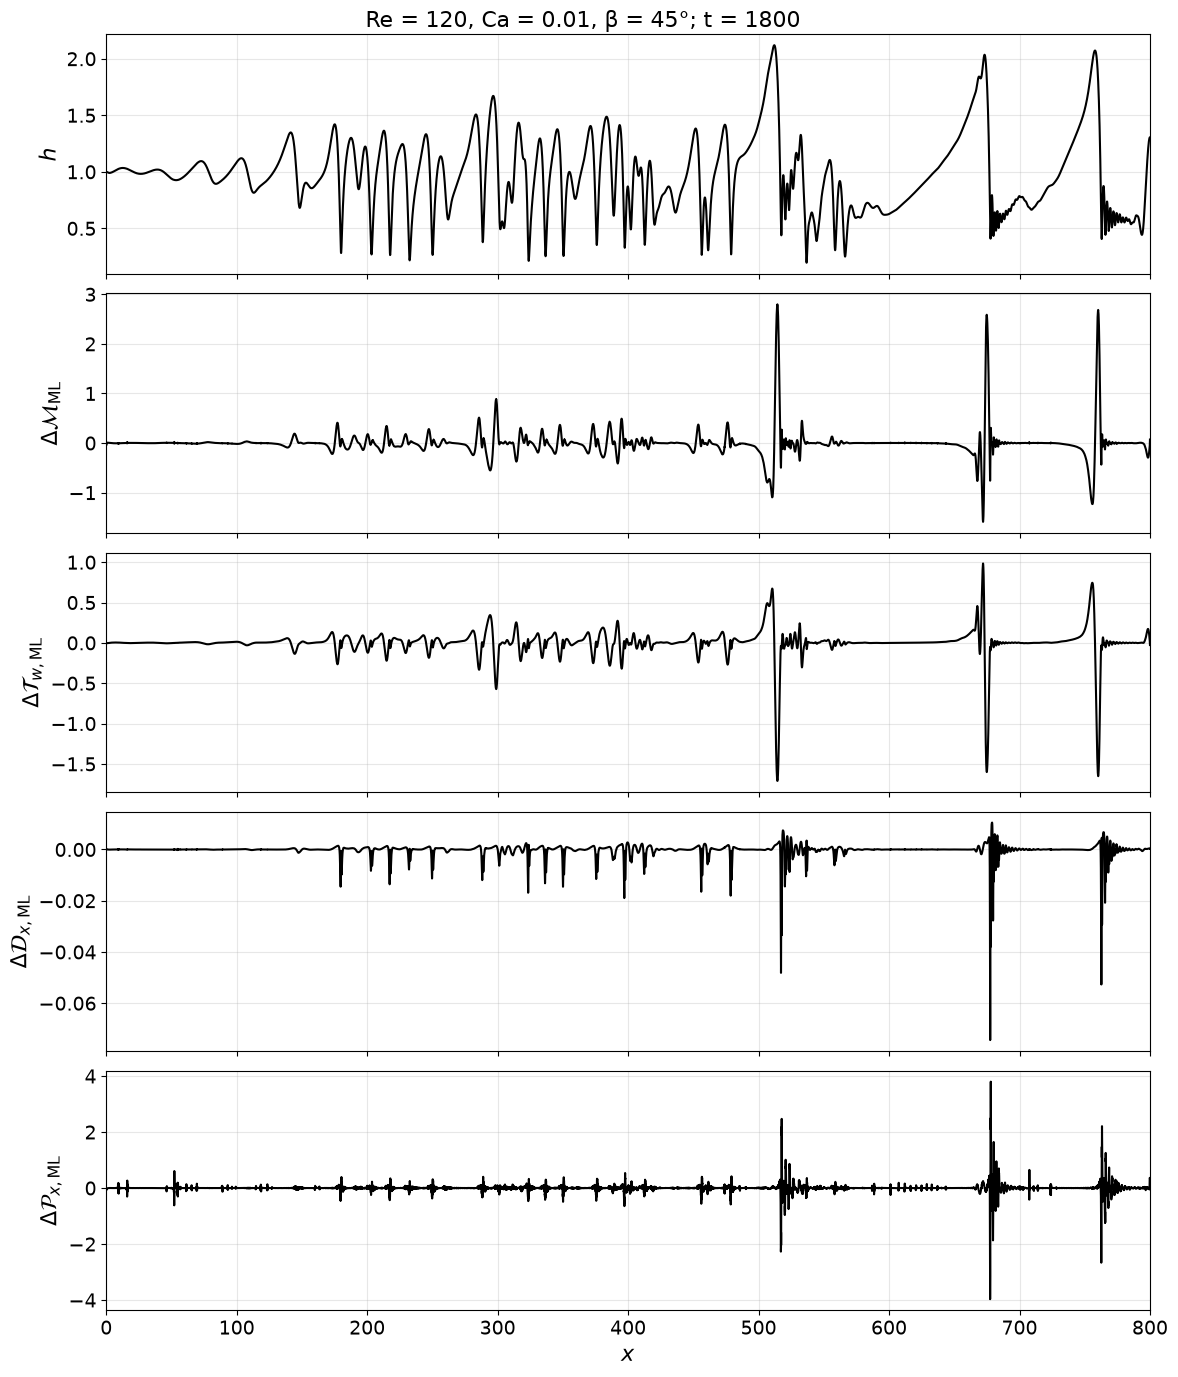

In [3]:
from scipy.signal import find_peaks

X_LIMITS = (0,800)

LINE_WIDTH = 1.5
LABEL_FONT_SIZE = 16
TICK_FONT_SIZE = 14
TITLE_FONT_SIZE = 16

# PDF export
SAVE_FIGURES = False
SAVE_FOLDER = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/codes/data-preprocessing/notebooks/Figures/DNS")
PNG_DPI = 300
FIGURE_NAME = (
    f"closures_Re{RE:03d}_Ca{ca_tag}_"
    f"beta{beta_tag}_t{selected_time:g}"
)

HEIGHT_PROMINENCE = 0.01  # Minimum prominence in height units

height = np.asarray(profiles["h"]).squeeze()
x_plot = np.asarray(x).squeeze()

max_indices, _ = find_peaks(height, prominence=HEIGHT_PROMINENCE)
min_indices, _ = find_peaks(-height, prominence=HEIGHT_PROMINENCE)

x_maxima = x_plot[max_indices]
x_minima = x_plot[min_indices]

if X_LIMITS is not None:
    xmin, xmax = X_LIMITS
    x_maxima = x_maxima[(x_maxima >= xmin) & (x_maxima <= xmax)]
    x_minima = x_minima[(x_minima >= xmin) & (x_minima <= xmax)]

fig, axes = plt.subplots(
    len(QUANTITIES),
    1,
    figsize=(12, 2.8 * len(QUANTITIES)),
    sharex=True,
    squeeze=False,
)

for ax, name in zip(axes[:, 0], QUANTITIES):
    profile = (
        profiles["delta_M_ML_x"]
        if name == "delta_M_ML"
        else profiles[name]
    )

    ax.plot(
        x,
        profile,
        color="black",
        linewidth=LINE_WIDTH,
    )
    
#     for i, xpos in enumerate(x_maxima):
#         ax.axvline(
#             xpos,
#             color="tab:red",
#             linestyle="--",
#             linewidth=1.5,
#             alpha=0.7,
#             label="Height maximum" if i == 0 else "_nolegend_",
#         )

#     for i, xpos in enumerate(x_minima):
#         ax.axvline(
#             xpos,
#             color="tab:blue",
#             linestyle="--",
#             linewidth=1.5,
#             alpha=0.7,
#             label="Height minimum" if i == 0 else "_nolegend_",
#         )

    ax.set_ylabel(
        PLOT_LABELS[name],
        fontsize=LABEL_FONT_SIZE,
    )
    ax.tick_params(
        axis="both",
        which="both",
        labelsize=TICK_FONT_SIZE,
    )
    ax.xaxis.get_offset_text().set_fontsize(TICK_FONT_SIZE)
    ax.yaxis.get_offset_text().set_fontsize(TICK_FONT_SIZE)
    ax.grid(alpha=0.3)

    if X_LIMITS is not None:
        ax.set_xlim(*X_LIMITS)

axes[-1, 0].set_xlabel(r"$x$", fontsize=LABEL_FONT_SIZE)

fig.suptitle(
    f"Re = {RE:g}, Ca = {CA:g}, β = {BETA:g}°; "
    f"t = {selected_time:g}",
    fontsize=TITLE_FONT_SIZE,
)

fig.tight_layout()

if SAVE_FIGURES:
    SAVE_FOLDER.mkdir(parents=True, exist_ok=True)

    for extension in ("pdf", "png"):
        output_path = SAVE_FOLDER / f"{FIGURE_NAME}.{extension}"
        fig.savefig(
            output_path,
            format=extension,
            dpi=PNG_DPI,
            bbox_inches="tight",
        )
        print(f"Saved: {output_path.resolve()}")
        
        
plt.show()

Plotting closure quantity PDFs

In [4]:
SAMPLES_PER_FILE = 5000
RANDOM_SEED = 42

SAMPLE_QUANTITIES = [
    "h",
    "q",
    "delta_M_ML",
    "delta_Tw_ML",
    "delta_Dx_ML",
    "delta_Px_ML",
]

statistics_rows = []

rng = np.random.default_rng(RANDOM_SEED)
sample_parts = {name: [] for name in SAMPLE_QUANTITIES}

files = sorted(DATA_DIR.glob("thinfilm_closure_data_*.h5"))

if not files:
    raise FileNotFoundError(f"No HDF5 files found in {DATA_DIR}")


def read_spatial_field(f, name, nx, nt):
    """Return a field with shape (nx, nt)."""
    array = np.asarray(f[name][:], dtype=float)

    if array.shape == (nx, nt):
        return array
    if array.shape == (nt, nx):
        return array.T

    raise ValueError(f"{name}: unexpected shape {array.shape}")


for filepath in files:
    with h5py.File(filepath, "r") as f:
        x_case = np.asarray(f["x"][:]).reshape(-1)
        t_case = np.asarray(f["t"][:]).reshape(-1)

        nx, nt = x_case.size, t_case.size

        h_case = read_spatial_field(f, "h", nx, nt)
        hx_case = read_spatial_field(f, "h_x", nx, nt)

        # Exclude the last 10% of the spatial domain.
        x_cutoff = x_case[0] + 0.9 * (x_case[-1] - x_case[0])

        valid = (
            np.isfinite(h_case)
            & (x_case[:, None] <= x_cutoff)
        )

        # Comment out this line to disable the |h_x| filter.
        valid &= np.isfinite(hx_case) & (np.abs(hx_case) >= 0.1)

        # Require finite values for every selected quantity.
        for name in SAMPLE_QUANTITIES:
            array = read_spatial_field(f, name, nx, nt)

            if name == "delta_M_ML":
                array = np.gradient(
                    array, x_case, axis=0, edge_order=2
                )

            valid &= np.isfinite(array)
            del array

        eligible = np.flatnonzero(valid)
        n_samples = min(SAMPLES_PER_FILE, eligible.size)

        if n_samples == 0:
            print(f"{filepath.name}: no eligible points; skipped")
            continue

        chosen = rng.choice(
            eligible,
            size=n_samples,
            replace=False,
        )

        ix, it = np.unravel_index(chosen, valid.shape)

        # Keep only sampled values, rather than retaining whole cases.
        for name in SAMPLE_QUANTITIES:
            array = read_spatial_field(f, name, nx, nt)

            if name == "delta_M_ML":
                array = np.gradient(
                    array, x_case, axis=0, edge_order=2
                )

            sample_parts[name].append(array[ix, it].copy())
            del array

    print(
        f"{filepath.name}: {n_samples:,} samples "
        f"from {eligible.size:,} eligible points"
    )

    del h_case, hx_case, valid, eligible

if not sample_parts[SAMPLE_QUANTITIES[0]]:
    raise ValueError("No samples remain after filtering.")

samples = {
    name: np.concatenate(parts)
    for name, parts in sample_parts.items()
}

print(f"\nTotal samples per quantity: {len(next(iter(samples.values()))):,}")

thinfilm_closure_data_Re010_Ca0_005_theta45.h5: 5,000 samples from 36,560 eligible points
thinfilm_closure_data_Re010_Ca0_010_theta45.h5: 5,000 samples from 230,613 eligible points
thinfilm_closure_data_Re010_Ca0_100_theta45.h5: 5,000 samples from 279,289 eligible points
thinfilm_closure_data_Re020_Ca0_010_theta45.h5: 5,000 samples from 356,797 eligible points
thinfilm_closure_data_Re020_Ca0_060_theta90.h5: 5,000 samples from 432,797 eligible points
thinfilm_closure_data_Re040_Ca0_002_theta45.h5: 5,000 samples from 131,722 eligible points
thinfilm_closure_data_Re040_Ca0_005_theta45.h5: 5,000 samples from 410,761 eligible points
thinfilm_closure_data_Re040_Ca0_010_theta90.h5: 5,000 samples from 536,363 eligible points
thinfilm_closure_data_Re040_Ca0_020_theta6_4.h5: 5,000 samples from 269,084 eligible points
thinfilm_closure_data_Re040_Ca0_040_theta45.h5: 5,000 samples from 299,935 eligible points
thinfilm_closure_data_Re040_Ca0_100_theta45.h5: 5,000 samples from 153,362 eligible points

In [5]:
for filepath in files:
    with h5py.File(filepath, "r") as f:
        x_case = np.asarray(f["x"][:]).reshape(-1)
        t_case = np.asarray(f["t"][:]).reshape(-1)
        nx, nt = x_case.size, t_case.size

        h_case = read_spatial_field(f, "h", nx, nt)
        hx_case = read_spatial_field(f, "h_x", nx, nt)

        x_cutoff = x_case[0] + 0.9 * (x_case[-1] - x_case[0])

        valid = (
            np.isfinite(h_case)
            & (x_case[:, None] <= x_cutoff)
            & np.isfinite(hx_case)
            & (np.abs(hx_case) >= 0.1)
        )

        def load_quantity(name):
            array = read_spatial_field(f, name, nx, nt)
            if name == "delta_M_ML":
                array = np.gradient(
                    array, x_case, axis=0, edge_order=2
                )
            return array

        # Use the same set of points for every quantity.
        for name in SAMPLE_QUANTITIES:
            array = load_quantity(name)
            valid &= np.isfinite(array)
            del array

        n_valid = int(valid.sum())
        if n_valid == 0:
            print(f"{filepath.name}: no eligible points; skipped")
            continue

        simulation = filepath.stem.removeprefix("thinfilm_closure_data_")

        for name in SAMPLE_QUANTITIES:
            array = load_quantity(name)
            values = array[valid]

            statistics_rows.append({
                "simulation": simulation,
                # Identify the differentiated momentum residual correctly.
                "quantity": "delta_M_ML_x" if name == "delta_M_ML" else name,
                "mean": float(np.mean(values)),
                "rms": float(np.sqrt(np.mean(values**2))),
                "n_points": n_valid,
            })

            del array, values

        del h_case, hx_case, valid

if not statistics_rows:
    raise ValueError("No eligible points remain after filtering.")

statistics_df = pd.DataFrame(statistics_rows)

quantity_order = [
    "delta_M_ML_x" if name == "delta_M_ML" else name
    for name in SAMPLE_QUANTITIES
]

mean_df = statistics_df.pivot(
    index="simulation", columns="quantity", values="mean"
).reindex(columns=quantity_order)

rms_df = statistics_df.pivot(
    index="simulation", columns="quantity", values="rms"
).reindex(columns=quantity_order)

print("Mean values:")
display(mean_df.style.format("{:.6g}"))

print("RMS values:")
display(rms_df.style.format("{:.6g}"))

Mean values:


quantity,h,q,delta_M_ML_x,delta_Tw_ML,delta_Dx_ML,delta_Px_ML
simulation,,,,,,
Re010_Ca0_005_theta45,0.976014,1.11093,0.0570388,-0.0296845,-0.00930618,-0.0342994
Re010_Ca0_010_theta45,0.999321,1.21001,0.146087,-0.104122,-0.0141275,-0.0453296
Re010_Ca0_100_theta45,1.36169,2.23304,0.109296,-0.126426,-0.0247965,-0.132878
Re020_Ca0_010_theta45,0.950269,1.08153,0.210108,-0.140381,-0.00879303,-0.0297333
Re020_Ca0_060_theta90,1.35129,2.05971,0.129051,-0.12879,-0.0125514,-0.032296
Re040_Ca0_002_theta45,0.85188,0.836971,0.107751,-0.0579093,-0.00251558,-0.0107124
Re040_Ca0_005_theta45,0.861419,0.849047,0.142863,-0.0850631,-0.00341743,-0.0124004
Re040_Ca0_010_theta90,1.05741,1.29727,0.134978,-0.0893946,-0.00456802,-0.0155391
Re040_Ca0_020_theta6_4,0.872525,0.762551,0.050908,-0.0400832,-0.00273021,-0.0145406


RMS values:


quantity,h,q,delta_M_ML_x,delta_Tw_ML,delta_Dx_ML,delta_Px_ML
simulation,,,,,,
Re010_Ca0_005_theta45,1.00366,1.32443,0.171785,0.139268,0.0146041,0.417069
Re010_Ca0_010_theta45,1.05078,1.61169,0.644739,0.428174,0.0338102,0.532106
Re010_Ca0_100_theta45,1.41001,2.52976,1.49086,0.972202,0.31886,4.70659
Re020_Ca0_010_theta45,1.03014,1.51675,0.699912,0.455475,0.0250014,0.463141
Re020_Ca0_060_theta90,1.42174,2.38525,2.0086,1.26732,0.143036,3.37833
Re040_Ca0_002_theta45,0.912365,1.10631,0.287892,0.190339,0.0041404,0.232506
Re040_Ca0_005_theta45,0.940057,1.18003,0.531,0.33621,0.00810278,0.222511
Re040_Ca0_010_theta90,1.18528,1.77815,1.20483,0.750939,0.0169561,0.430991
Re040_Ca0_020_theta6_4,0.89196,0.863207,0.143656,0.102241,0.00924746,0.252891


In [6]:
def sample_comparison_cases(cases, quantities, filter_hx=True):
    rng = np.random.default_rng(RANDOM_SEED)
    results = {}

    for re_value, ca_value, beta_value, label in cases:
        ca_tag = f"{ca_value:.3f}".replace(".", "_")
        beta_tag = f"{beta_value:g}".replace(".", "_")
        filepath = DATA_DIR / (
            f"thinfilm_closure_data_Re{re_value:03d}_"
            f"Ca{ca_tag}_theta{beta_tag}.h5"
        )

        if not filepath.is_file():
            raise FileNotFoundError(filepath)

        with h5py.File(filepath, "r") as f:
            x_case = np.asarray(f["x"][:]).reshape(-1)
            t_case = np.asarray(f["t"][:]).reshape(-1)
            nx, nt = x_case.size, t_case.size

            h_case = read_spatial_field(f, "h", nx, nt)
            cutoff = x_case[0] + 0.9 * (x_case[-1] - x_case[0])

            valid = (
                np.isfinite(h_case)
                & (x_case[:, None] <= cutoff)
            )
            del h_case

            if filter_hx:
                h = read_spatial_field(f, "h", nx, nt)
                hx = read_spatial_field(f, "h_x", nx, nt)

                valid &= (np.isfinite(h) & np.isfinite(hx) & (np.abs(h - 1.0) > 0.05) & (np.abs(hx) >= 0.1))

                del h, hx

            # Check every target before selecting shared sample points.
            for name in quantities:
                array = read_spatial_field(f, name, nx, nt)
                if name == "delta_M_ML":
                    array = np.gradient(
                        array, x_case, axis=0, edge_order=2
                    )
                valid &= np.isfinite(array)
                del array

            eligible = np.flatnonzero(valid)
            count = min(SAMPLES_PER_CASE, eligible.size)

            if count == 0:
                raise ValueError(f"{filepath.name}: no eligible points")

            chosen = rng.choice(eligible, count, replace=False)
            ix, it = np.unravel_index(chosen, valid.shape)

            results[label] = {}
            for name in quantities:
                array = read_spatial_field(f, name, nx, nt)
                if name == "delta_M_ML":
                    array = np.gradient(
                        array, x_case, axis=0, edge_order=2
                    )
                results[label][name] = array[ix, it].copy()
                del array

        print(f"{filepath.name}: {count:,} samples")

    return results


def plot_comparison_pdfs(case_samples, quantities, title, filename):
    COLORS = ["tab:purple", "tab:blue", "tab:green", "tab:orange", "tab:red"]
    ALPHAS = [0.35, 0.5, 0.65, 0.75, 0.90]

    fig, axes = plt.subplots(
        len(quantities), 1,
        figsize=(10, 2.8 * len(quantities)),
        squeeze=False,
    )

    for ax, name in zip(axes[:, 0], quantities):
        pooled = np.concatenate([
            values[name] for values in case_samples.values()
        ])
        limits = PDF_XLIMS.get(name)

        if limits is None:
            bins = np.histogram_bin_edges(pooled, bins=N_BINS)
        else:
            lo, hi = limits

            if lo >= hi:
                raise ValueError(f"{name}: xlim must satisfy lo < hi")

            # Exactly N_BINS within the specified limits.
            bins = np.linspace(lo, hi, N_BINS + 1)

            # Include outside values in tail bins to preserve full-data normalization.
            if pooled.min() < lo:
                bins = np.r_[pooled.min(), bins]
            if pooled.max() > hi:
                bins = np.r_[bins, pooled.max()]

        for j, (label, values) in enumerate(case_samples.items()):
            ax.hist(
                values[name],
                bins=bins,
                density=True,
                histtype="bar",
                color=COLORS[j % len(COLORS)],
                alpha=ALPHAS[j % len(ALPHAS)],
                edgecolor="none",
                label=label,
            )
        
        limits = PDF_XLIMS.get(name)
        if limits is not None:
            ax.set_xlim(*limits)

        ax.set_xlabel(PLOT_LABELS[name], fontsize=LABEL_FONT_SIZE)
        ax.set_ylabel("Probability density", fontsize=LABEL_FONT_SIZE)
        ax.tick_params(axis="both", labelsize=TICK_FONT_SIZE)
        ax.xaxis.get_offset_text().set_fontsize(TICK_FONT_SIZE)
        ax.yaxis.get_offset_text().set_fontsize(TICK_FONT_SIZE)
        ax.legend(fontsize=LEGEND_FONT_SIZE)
        ax.grid(alpha=0.3)

        if LOG_PDF:
            ax.set_yscale("log")

    fig.suptitle(title, fontsize=TITLE_FONT_SIZE)
    fig.tight_layout()

    if SAVE_FIGURES:
        SAVE_FOLDER.mkdir(parents=True, exist_ok=True)
        for extension in ("pdf", "png"):
            path = SAVE_FOLDER / f"{filename}.{extension}"
            fig.savefig(
                path, format=extension,
                dpi=PNG_DPI, bbox_inches="tight",
            )
            print(f"Saved: {path.resolve()}")

    plt.show()
    return fig

thinfilm_closure_data_Re040_Ca0_002_theta45.h5: 20,000 samples
thinfilm_closure_data_Re040_Ca0_005_theta45.h5: 20,000 samples
thinfilm_closure_data_Re040_Ca0_040_theta45.h5: 20,000 samples


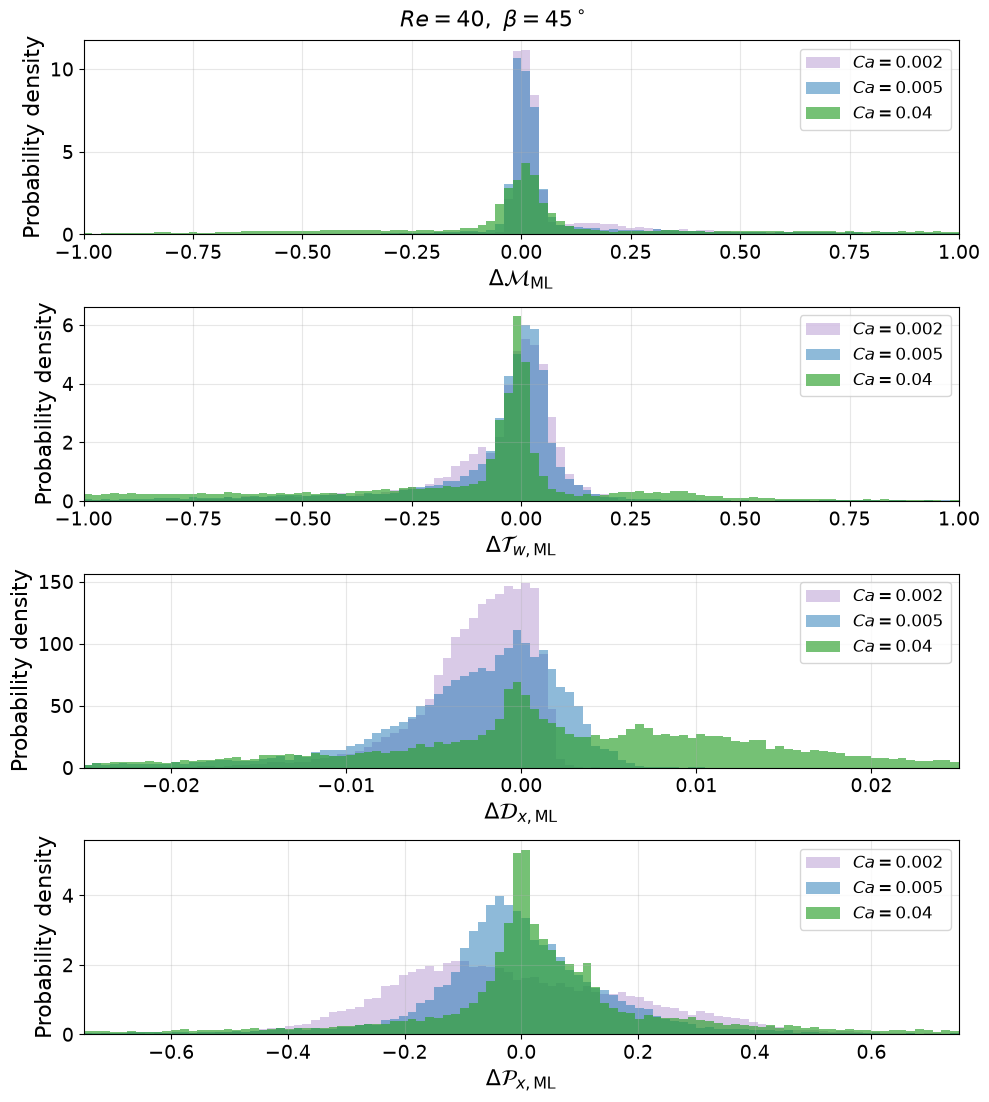

In [7]:
RE_FIXED = 40
BETA_FIXED = 45
CA_VALUES = [0.002, 0.005, 0.04]

SAMPLE_QUANTITIES = [
    "delta_M_ML", "delta_Tw_ML", "delta_Dx_ML", "delta_Px_ML",
]

SAMPLES_PER_CASE = 20000
FILTER_HX = True  # False disables the |h_x| >= 0.1 filter.
RANDOM_SEED = 42

LINE_WIDTH = 1.5
LABEL_FONT_SIZE = 16
TICK_FONT_SIZE = 14
LEGEND_FONT_SIZE = 12
TITLE_FONT_SIZE = 16
N_BINS = 100
LOG_PDF = False

SAVE_FIGURES = False
SAVE_FOLDER = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/codes/data-preprocessing/notebooks/Figures/DNS")
PNG_DPI = 300

PDF_XLIMS = {
    "delta_M_ML": (-1, 1),
    "delta_Tw_ML": (-1, 1),
    "delta_Dx_ML": (-0.025, 0.025),
    "delta_Px_ML": (-0.75, 0.75),
}

cases_ca = [
    (RE_FIXED, ca, BETA_FIXED, rf"$Ca={ca:g}$")
    for ca in CA_VALUES
]

samples_ca = sample_comparison_cases(
    cases_ca, SAMPLE_QUANTITIES, filter_hx=FILTER_HX
)

fig_ca = plot_comparison_pdfs(
    samples_ca,
    SAMPLE_QUANTITIES,
    rf"$Re={RE_FIXED:g},\ \beta={BETA_FIXED:g}^\circ$",
    f"PDFs_varying_Ca_Re{RE_FIXED:03d}_beta{BETA_FIXED:g}",
)

thinfilm_closure_data_Re020_Ca0_010_theta45.h5: 20,000 samples
thinfilm_closure_data_Re120_Ca0_010_theta45.h5: 20,000 samples
thinfilm_closure_data_Re200_Ca0_010_theta45.h5: 20,000 samples


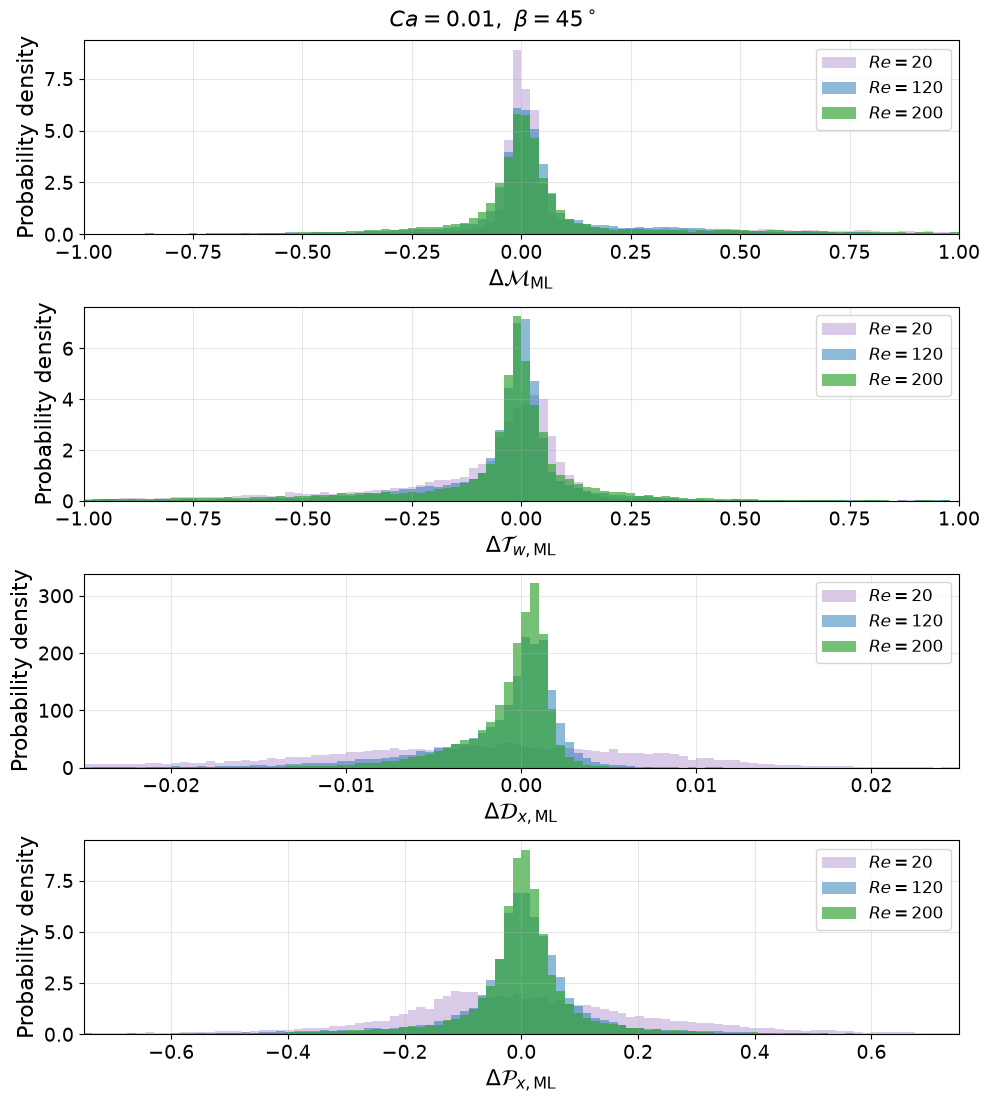

In [8]:
BETA_FIXED = 45
CA_FIXED = 0.01
RE_VALUES = [20, 120, 200]

FILTER_HX = True
SAVE_FIGURES = False
SAVE_FOLDER = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/codes/data-preprocessing/notebooks/Figures/DNS")

PDF_XLIMS = {
    "delta_M_ML": (-1, 1),
    "delta_Tw_ML": (-1, 1),
    "delta_Dx_ML": (-0.025, 0.025),
    "delta_Px_ML": (-0.75, 0.75),
}

cases_re = [
    (re_value, CA_FIXED, BETA_FIXED, rf"$Re={re_value:g}$")
    for re_value in RE_VALUES
]

samples_re = sample_comparison_cases(
    cases_re, SAMPLE_QUANTITIES, filter_hx=FILTER_HX
)

fig_re = plot_comparison_pdfs(
    samples_re,
    SAMPLE_QUANTITIES,
    rf"$Ca={CA_FIXED:g},\ \beta={BETA_FIXED:g}^\circ$",
    f"PDFs_varying_Re_Ca{CA_FIXED:g}_beta{BETA_FIXED:g}",
)

thinfilm_closure_data_Re120_Ca0_010_theta6_4.h5: 20,000 samples
thinfilm_closure_data_Re120_Ca0_010_theta45.h5: 20,000 samples
thinfilm_closure_data_Re120_Ca0_010_theta90.h5: 20,000 samples


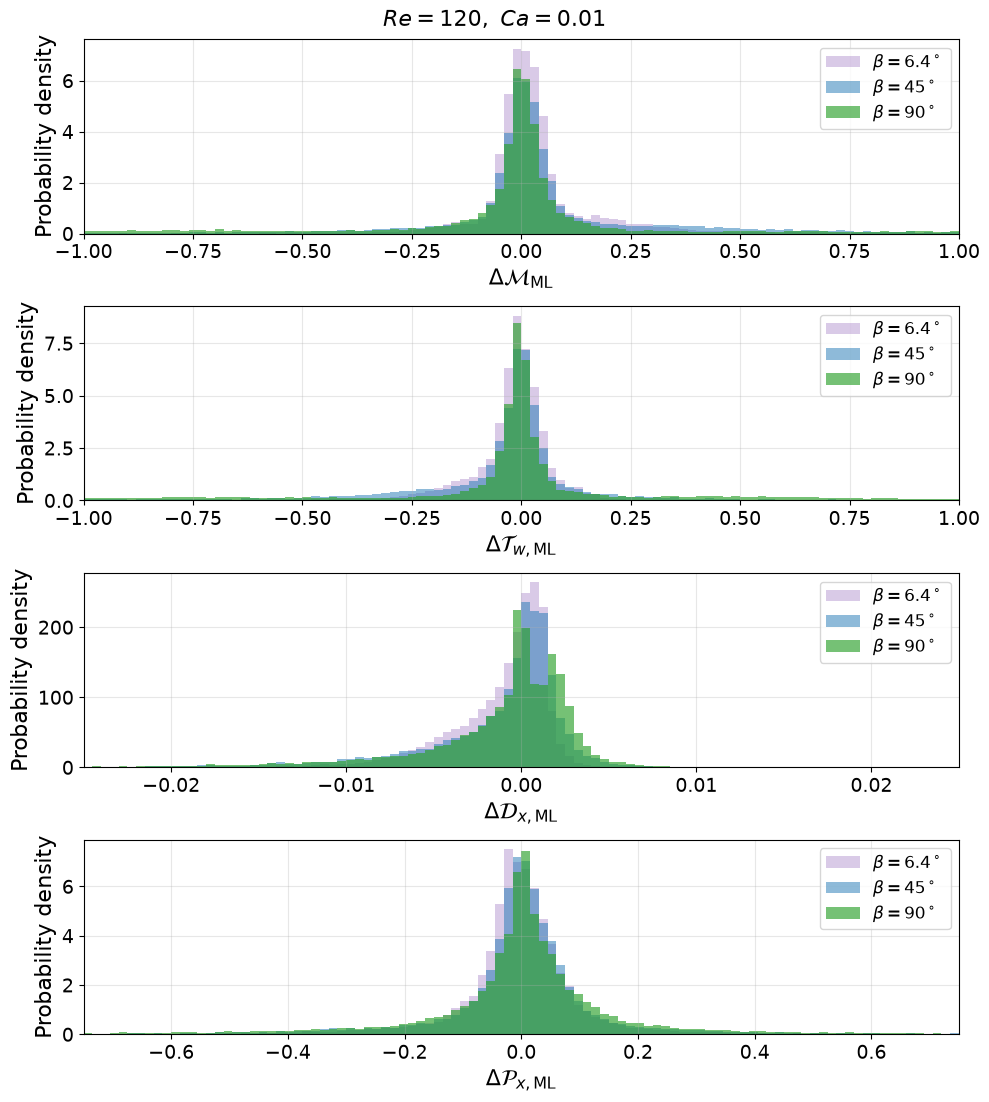

In [9]:
RE_FIXED = 120
CA_FIXED = 0.01
BETA_VALUES = [6.4, 45, 90]

FILTER_HX = True
SAVE_FIGURES = False
SAVE_FOLDER = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/codes/data-preprocessing/notebooks/Figures/DNS")

PDF_XLIMS = {
    "delta_M_ML": (-1, 1),
    "delta_Tw_ML": (-1, 1),
    "delta_Dx_ML": (-0.025, 0.025),
    "delta_Px_ML": (-0.75, 0.75),
}

cases_beta = [
    (
        RE_FIXED, CA_FIXED, beta,
        rf"$\beta={beta:g}^\circ$",
    )
    for beta in BETA_VALUES
]

samples_beta = sample_comparison_cases(
    cases_beta, SAMPLE_QUANTITIES, filter_hx=FILTER_HX
)

fig_beta = plot_comparison_pdfs(
    samples_beta,
    SAMPLE_QUANTITIES,
    rf"$Re={RE_FIXED:g},\ Ca={CA_FIXED:g}$",
    f"PDFs_varying_beta_Re{RE_FIXED:03d}_Ca{CA_FIXED:g}",
)

thinfilm_closure_data_Re080_Ca0_010_theta45.h5: 20,000 samples
thinfilm_closure_data_Re080_Ca0_010_theta90.h5: 20,000 samples


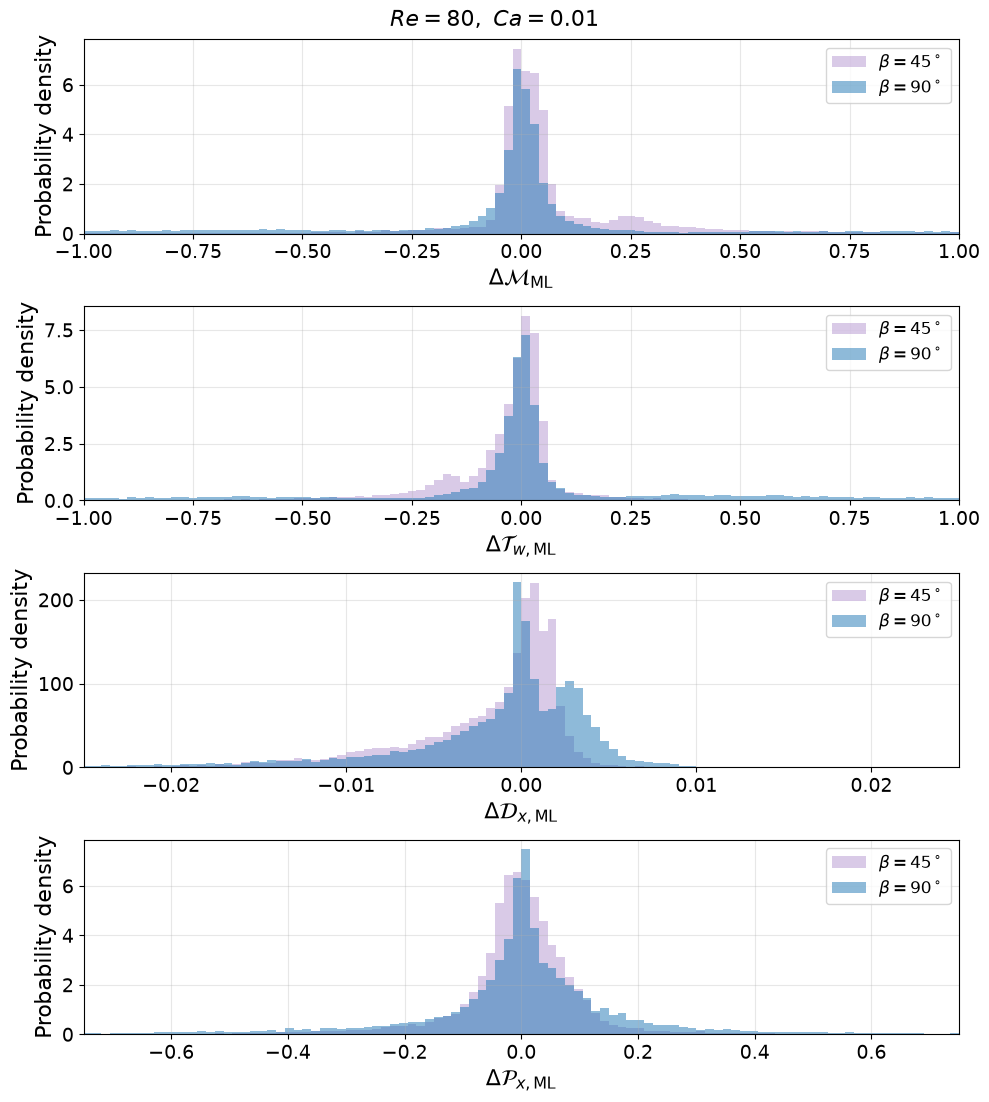

In [10]:
RE_FIXED = 80
CA_FIXED = 0.01
BETA_VALUES = [45, 90]

FILTER_HX = True
SAVE_FIGURES = False
SAVE_FOLDER = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/codes/data-preprocessing/notebooks/Figures/DNS")

PDF_XLIMS = {
    "delta_M_ML": (-1, 1),
    "delta_Tw_ML": (-1, 1),
    "delta_Dx_ML": (-0.025, 0.025),
    "delta_Px_ML": (-0.75, 0.75),
}

cases_beta = [
    (
        RE_FIXED, CA_FIXED, beta,
        rf"$\beta={beta:g}^\circ$",
    )
    for beta in BETA_VALUES
]

samples_beta = sample_comparison_cases(
    cases_beta, SAMPLE_QUANTITIES, filter_hx=FILTER_HX
)

fig_beta = plot_comparison_pdfs(
    samples_beta,
    SAMPLE_QUANTITIES,
    rf"$Re={RE_FIXED:g},\ Ca={CA_FIXED:g}$",
    f"PDFs_varying_beta_Re{RE_FIXED:03d}_Ca{CA_FIXED:g}",
)

In [11]:
def plot_comparison_norm_pdfs(case_samples, quantities, title, filename):
    
    standardized_samples = {}

    for label, values in case_samples.items():
        standardized_samples[label] = {}

        for name in quantities:
            array = np.asarray(values[name], dtype=float)
            mean = np.mean(array)
            variance = np.var(array, ddof=0)
            std = np.sqrt(variance)

            if not np.isfinite(std) or std <= 0:
                raise ValueError(
                    f"{label}/{name}: cannot standardize a constant "
                    "or non-finite quantity."
                )

            standardized_samples[label][name] = (array - mean) / std

            print(
                f"{label}, {name}: "
                f"mean={mean:.6g}, variance={variance:.6g}, std={std:.6g}"
            )

    # The rest of the function now plots standardized samples.
    case_samples = standardized_samples
    
    COLORS = ["tab:purple", "tab:blue", "tab:green", "tab:orange", "tab:red"]
    ALPHAS = [0.35, 0.5, 0.65, 0.75, 0.90]

    fig, axes = plt.subplots(
        len(quantities), 1,
        figsize=(10, 2.8 * len(quantities)),
        squeeze=False,
    )

    for ax, name in zip(axes[:, 0], quantities):
        pooled = np.concatenate([
            values[name] for values in case_samples.values()
        ])
        limits = PDF_XLIMS.get(name)

        if limits is None:
            bins = np.histogram_bin_edges(pooled, bins=N_BINS)
        else:
            lo, hi = limits

            if lo >= hi:
                raise ValueError(f"{name}: xlim must satisfy lo < hi")

            # Exactly N_BINS within the specified limits.
            bins = np.linspace(lo, hi, N_BINS + 1)

            # Include outside values in tail bins to preserve full-data normalization.
            if pooled.min() < lo:
                bins = np.r_[pooled.min(), bins]
            if pooled.max() > hi:
                bins = np.r_[bins, pooled.max()]

        for j, (label, values) in enumerate(case_samples.items()):
            ax.hist(
                values[name],
                bins=bins,
                density=True,
                histtype="bar",
                color=COLORS[j % len(COLORS)],
                alpha=ALPHAS[j % len(ALPHAS)],
                edgecolor="none",
                label=label,
            )
        
        limits = PDF_XLIMS.get(name)
        if limits is not None:
            ax.set_xlim(*limits)

        ax.set_xlabel(
            "Standardized " + PLOT_LABELS[name],
            fontsize=LABEL_FONT_SIZE,
        )
        ax.set_ylabel("Probability density", fontsize=LABEL_FONT_SIZE)
        ax.tick_params(axis="both", labelsize=TICK_FONT_SIZE)
        ax.xaxis.get_offset_text().set_fontsize(TICK_FONT_SIZE)
        ax.yaxis.get_offset_text().set_fontsize(TICK_FONT_SIZE)
        ax.legend(fontsize=LEGEND_FONT_SIZE)
        ax.grid(alpha=0.3)

        if LOG_PDF:
            ax.set_yscale("log")

    fig.suptitle(title, fontsize=TITLE_FONT_SIZE)
    fig.tight_layout()

    if SAVE_FIGURES:
        SAVE_FOLDER.mkdir(parents=True, exist_ok=True)
        for extension in ("pdf", "png"):
            path = SAVE_FOLDER / f"{filename}.{extension}"
            fig.savefig(
                path, format=extension,
                dpi=PNG_DPI, bbox_inches="tight",
            )
            print(f"Saved: {path.resolve()}")

    plt.show()
    return fig

thinfilm_closure_data_Re020_Ca0_010_theta45.h5: 20,000 samples
thinfilm_closure_data_Re120_Ca0_010_theta45.h5: 20,000 samples
thinfilm_closure_data_Re200_Ca0_010_theta45.h5: 20,000 samples
$Re=20$, delta_M_ML: mean=0.214818, variance=0.453097, std=0.673125
$Re=20$, delta_Tw_ML: mean=-0.14335, variance=0.191315, std=0.437395
$Re=20$, delta_Dx_ML: mean=-0.00891448, variance=0.000562537, std=0.0237179
$Re=20$, delta_Px_ML: mean=-0.0294529, variance=0.226017, std=0.475412
$Re=120$, delta_M_ML: mean=0.130326, variance=0.377349, std=0.614287
$Re=120$, delta_Tw_ML: mean=-0.0840684, variance=0.148431, std=0.385267
$Re=120$, delta_Dx_ML: mean=-0.00159773, variance=2.79248e-05, std=0.00528439
$Re=120$, delta_Px_ML: mean=-0.00478311, variance=0.0578354, std=0.24049
$Re=200$, delta_M_ML: mean=0.108011, variance=0.337603, std=0.581036
$Re=200$, delta_Tw_ML: mean=-0.07122, variance=0.132887, std=0.364536
$Re=200$, delta_Dx_ML: mean=-0.000874634, variance=9.81132e-06, std=0.0031323
$Re=200$, delta_Px

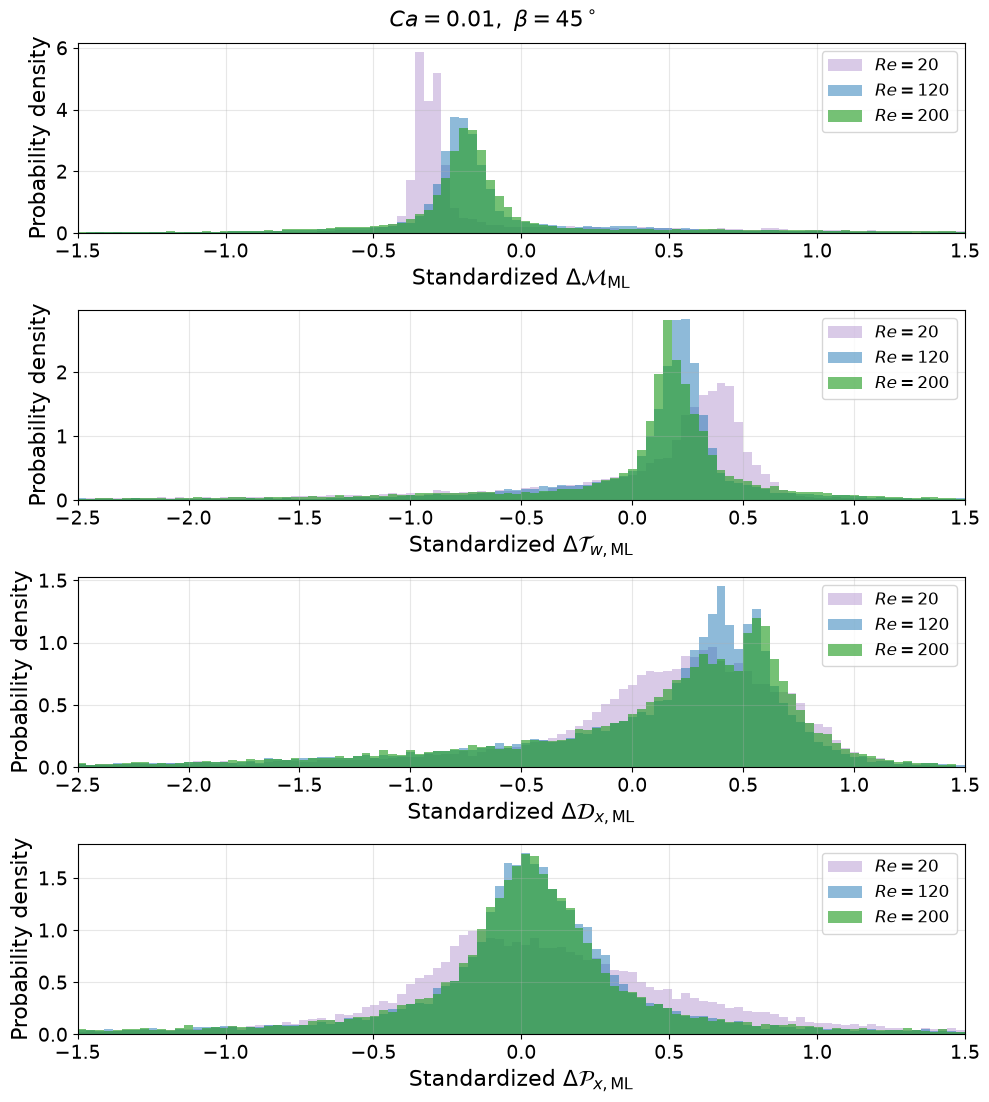

In [12]:
BETA_FIXED = 45
CA_FIXED = 0.01
RE_VALUES = [20, 120, 200]

FILTER_HX = True
SAVE_FIGURES = False
SAVE_FOLDER = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/codes/data-preprocessing/notebooks/Figures/DNS")

PDF_XLIMS = {
    "delta_M_ML": (-1.5, 1.5),
    "delta_Tw_ML": (-2.5, 1.5),
    "delta_Dx_ML": (-2.5, 1.5),
    "delta_Px_ML": (-1.5, 1.5),
}

cases_re = [
    (re_value, CA_FIXED, BETA_FIXED, rf"$Re={re_value:g}$")
    for re_value in RE_VALUES
]

samples_re = sample_comparison_cases(
    cases_re, SAMPLE_QUANTITIES, filter_hx=FILTER_HX
)

fig_re = plot_comparison_norm_pdfs(
    samples_re,
    SAMPLE_QUANTITIES,
    rf"$Ca={CA_FIXED:g},\ \beta={BETA_FIXED:g}^\circ$",
    f"PDFs_varying_Re_Ca{CA_FIXED:g}_beta{BETA_FIXED:g}",
)

thinfilm_closure_data_Re040_Ca0_002_theta45.h5: 20,000 samples
thinfilm_closure_data_Re040_Ca0_005_theta45.h5: 20,000 samples
thinfilm_closure_data_Re040_Ca0_040_theta45.h5: 20,000 samples
$Ca=0.002$, delta_M_ML: mean=0.11117, variance=0.0742146, std=0.272424
$Ca=0.002$, delta_Tw_ML: mean=-0.0594528, variance=0.0343882, std=0.185441
$Ca=0.002$, delta_Dx_ML: mean=-0.00263738, variance=1.13921e-05, std=0.00337522
$Ca=0.002$, delta_Px_ML: mean=-0.0119099, variance=0.0556502, std=0.235903
$Ca=0.005$, delta_M_ML: mean=0.149375, variance=0.286696, std=0.53544
$Ca=0.005$, delta_Tw_ML: mean=-0.0886942, variance=0.115686, std=0.340127
$Ca=0.005$, delta_Dx_ML: mean=-0.00374104, variance=6.05002e-05, std=0.00777819
$Ca=0.005$, delta_Px_ML: mean=-0.0150712, variance=0.0561449, std=0.236949
$Ca=0.04$, delta_M_ML: mean=0.317898, variance=1.68431, std=1.29781
$Ca=0.04$, delta_Tw_ML: mean=-0.251697, variance=0.649045, std=0.805633
$Ca=0.04$, delta_Dx_ML: mean=-0.00696291, variance=0.00268535, std=0.05

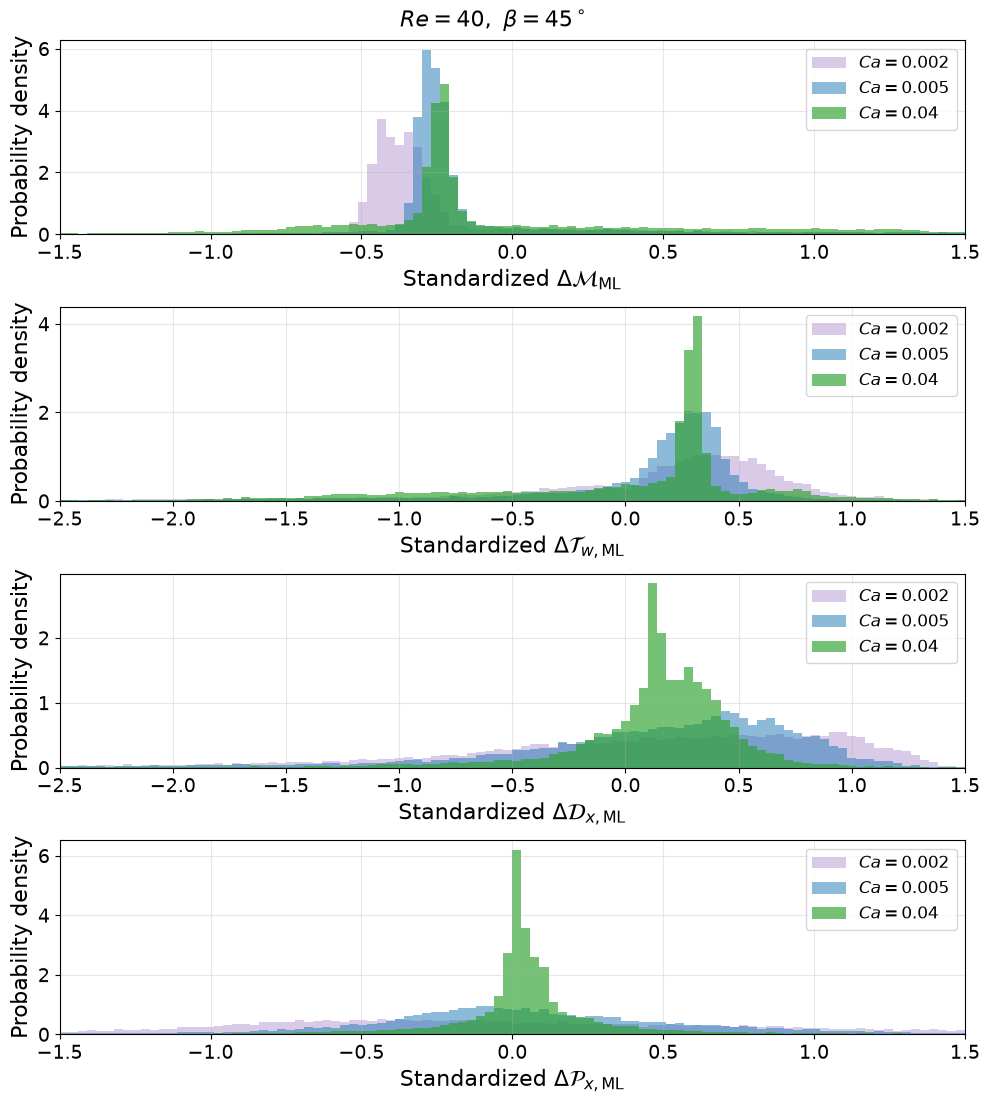

In [13]:
RE_FIXED = 40
BETA_FIXED = 45
CA_VALUES = [0.002, 0.005, 0.04]

SAMPLE_QUANTITIES = [
    "delta_M_ML", "delta_Tw_ML", "delta_Dx_ML", "delta_Px_ML",
]

SAMPLES_PER_CASE = 20000
FILTER_HX = True  # False disables the |h_x| >= 0.1 filter.
RANDOM_SEED = 42

LINE_WIDTH = 1.5
LABEL_FONT_SIZE = 16
TICK_FONT_SIZE = 14
LEGEND_FONT_SIZE = 12
TITLE_FONT_SIZE = 16
N_BINS = 100
LOG_PDF = False

SAVE_FIGURES = False
SAVE_FOLDER = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/codes/data-preprocessing/notebooks/Figures/DNS")
PNG_DPI = 300

PDF_XLIMS = {
    "delta_M_ML": (-1.5, 1.5),
    "delta_Tw_ML": (-2.5, 1.5),
    "delta_Dx_ML": (-2.5, 1.5),
    "delta_Px_ML": (-1.5, 1.5),
}

cases_ca = [
    (RE_FIXED, ca, BETA_FIXED, rf"$Ca={ca:g}$")
    for ca in CA_VALUES
]

samples_ca = sample_comparison_cases(
    cases_ca, SAMPLE_QUANTITIES, filter_hx=FILTER_HX
)

fig_ca = plot_comparison_norm_pdfs(
    samples_ca,
    SAMPLE_QUANTITIES,
    rf"$Re={RE_FIXED:g},\ \beta={BETA_FIXED:g}^\circ$",
    f"PDFs_varying_Ca_Re{RE_FIXED:03d}_beta{BETA_FIXED:g}",
)

thinfilm_closure_data_Re120_Ca0_010_theta6_4.h5: 20,000 samples
thinfilm_closure_data_Re120_Ca0_010_theta45.h5: 20,000 samples
thinfilm_closure_data_Re120_Ca0_010_theta90.h5: 20,000 samples
$\beta=6.4^\circ$, delta_M_ML: mean=0.0342917, variance=0.0170303, std=0.1305
$\beta=6.4^\circ$, delta_Tw_ML: mean=-0.0224379, variance=0.00877192, std=0.0936585
$\beta=6.4^\circ$, delta_Dx_ML: mean=-0.00121779, variance=9.16998e-06, std=0.0030282
$\beta=6.4^\circ$, delta_Px_ML: mean=-0.00541307, variance=0.0141249, std=0.118848
$\beta=45^\circ$, delta_M_ML: mean=0.120974, variance=0.373157, std=0.610865
$\beta=45^\circ$, delta_Tw_ML: mean=-0.0784737, variance=0.146384, std=0.382602
$\beta=45^\circ$, delta_Dx_ML: mean=-0.00160507, variance=2.91707e-05, std=0.00540099
$\beta=45^\circ$, delta_Px_ML: mean=-0.00489917, variance=0.0686857, std=0.26208
$\beta=90^\circ$, delta_M_ML: mean=0.143167, variance=1.03151, std=1.01563
$\beta=90^\circ$, delta_Tw_ML: mean=-0.0965548, variance=0.394455, std=0.628056


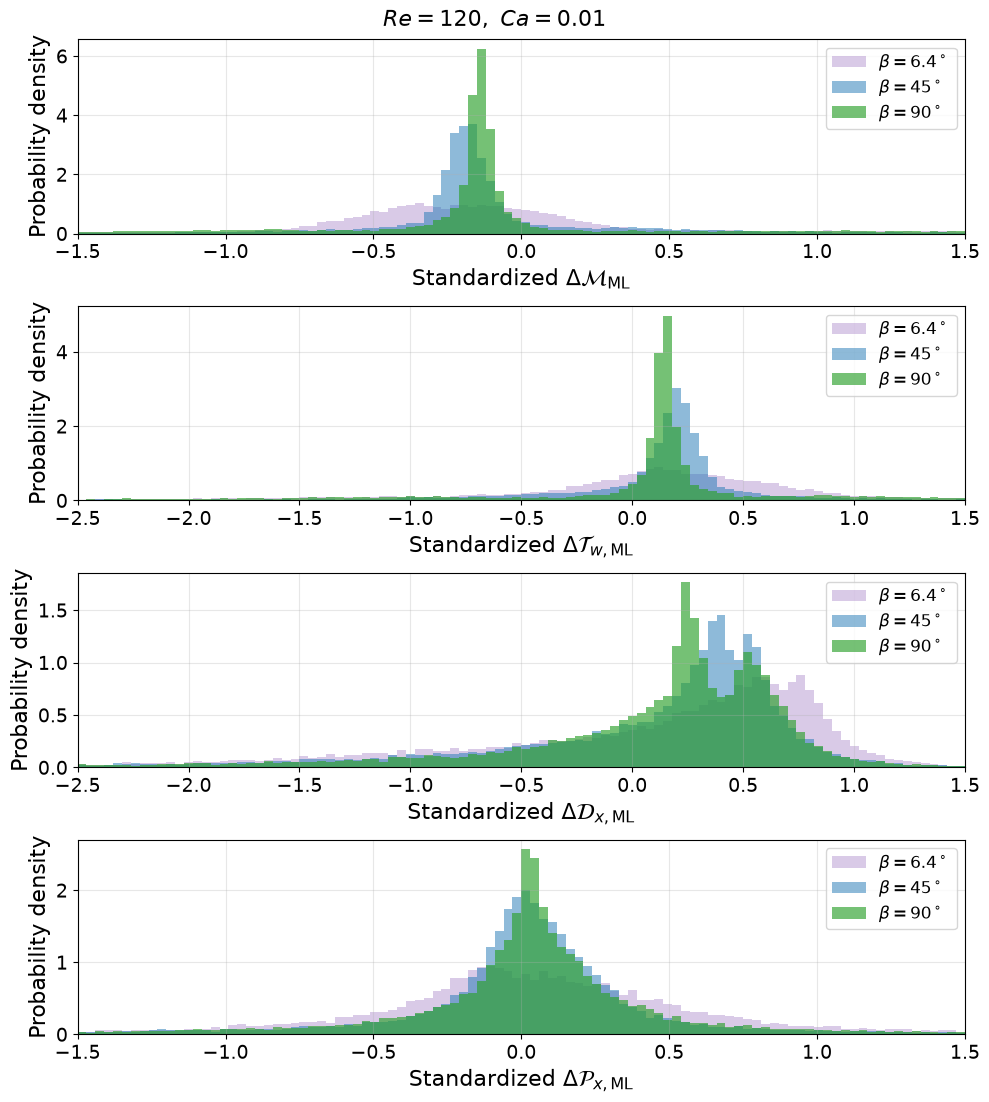

In [14]:
RE_FIXED = 120
CA_FIXED = 0.01
BETA_VALUES = [6.4, 45, 90]

FILTER_HX = True
SAVE_FIGURES = False
SAVE_FOLDER = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/codes/data-preprocessing/notebooks/Figures/DNS")

PDF_XLIMS = {
    "delta_M_ML": (-1.5, 1.5),
    "delta_Tw_ML": (-2.5, 1.5),
    "delta_Dx_ML": (-2.5, 1.5),
    "delta_Px_ML": (-1.5, 1.5),
}
cases_beta = [
    (
        RE_FIXED, CA_FIXED, beta,
        rf"$\beta={beta:g}^\circ$",
    )
    for beta in BETA_VALUES
]

samples_beta = sample_comparison_cases(
    cases_beta, SAMPLE_QUANTITIES, filter_hx=FILTER_HX
)

fig_beta = plot_comparison_norm_pdfs(
    samples_beta,
    SAMPLE_QUANTITIES,
    rf"$Re={RE_FIXED:g},\ Ca={CA_FIXED:g}$",
    f"PDFs_varying_beta_Re{RE_FIXED:03d}_Ca{CA_FIXED:g}",
)

In [15]:
x[1]-x[0]

np.float64(0.048828125)

In [16]:
import h5py
import numpy as np

FILE_PATH = DATA_DIR / "thinfilm_closure_data_Re040_Ca0_100_theta45.h5"
QOI = "dudy_wall"

# H_HALF_WIDTHS = np.array([0.0, 0.05, 0.10, 0.20, 0.40, 0.80])
# Q_HALF_WIDTHS = np.array([0.0, 0.05, 0.10, 0.20, 0.40, 0.80])

BLOCK_SIZE_X = 128

with h5py.File(FILE_PATH, "r") as f:
    x = np.asarray(f["x"][:], dtype=float).reshape(-1)
    t = np.asarray(f["t"][:], dtype=float).reshape(-1)
    nx, nt = len(x), len(t)

    h = read_spatial_field(f, "h", nx, nt)
    q = read_spatial_field(f, "q", nx, nt)
    y = read_spatial_field(f, QOI, nx, nt)

dx = np.mean(np.diff(x))
H_HALF_WIDTHS = np.arange(41, dtype=float) * dx
Q_HALF_WIDTHS = np.arange(41, dtype=float) * dx

if dx <= 0 or not np.allclose(np.diff(x), dx):
    raise ValueError("This implementation requires an increasing uniform grid.")

if np.any(H_HALF_WIDTHS < 0) or np.any(Q_HALF_WIDTHS < 0):
    raise ValueError("Half-widths must be non-negative.")

# Reynolds-type fluctuations: subtract the time mean at each x.
def fluctuations(field):
    field = np.where(np.isfinite(field), field, np.nan)
    return field - np.nanmean(field, axis=1, keepdims=True)

hp = fluctuations(h)
qp = fluctuations(q)
yp = fluctuations(y)

# Include all grid points lying inside each requested physical half-width.
kh = np.floor(H_HALF_WIDTHS / dx + 1e-9).astype(int)
kq = np.floor(Q_HALF_WIDTHS / dx + 1e-9).astype(int)
K = int(max(kh.max(), kq.max()))

if 2 * K >= nx:
    raise ValueError("The largest neighborhood is wider than the domain.")

offsets = np.arange(-K, K + 1)
separations = offsets * dx
window_size = len(offsets)

# Columns: h' at each offset, q' at each offset, local Y'.
n_columns = 2 * window_size + 1
sum_values = np.zeros(n_columns)
sum_products = np.zeros((n_columns, n_columns))
n_pairs = 0

# Common centers ensure every width uses the same x,t observations.
for start in range(K, nx - K, BLOCK_SIZE_X):
    stop = min(start + BLOCK_SIZE_X, nx - K)

    columns = [
        hp[start + offset:stop + offset].reshape(-1)
        for offset in offsets
    ]
    columns += [
        qp[start + offset:stop + offset].reshape(-1)
        for offset in offsets
    ]
    columns.append(yp[start:stop].reshape(-1))

    block = np.column_stack(columns)
    block = block[np.all(np.isfinite(block), axis=1)]

    if len(block):
        sum_values += block.sum(axis=0)
        sum_products += block.T @ block
        n_pairs += len(block)

if n_pairs < 2:
    raise ValueError("Not enough finite observations.")

mean_values = sum_values / n_pairs
covariance = (
    sum_products / n_pairs
    - np.outer(mean_values, mean_values)
)
covariance = 0.5 * (covariance + covariance.T)

if covariance[-1, -1] <= 0:
    raise ValueError("The QoI has no fluctuation variance.")

print(f"QoI: {QOI}")
print(f"Grid spacing: {dx:.6g}")
print(f"Included x,t observations: {n_pairs:,}")
print("Actual h half-widths:", kh * dx)
print("Actual q half-widths:", kq * dx)

QoI: dudy_wall
Grid spacing: 0.0488281
Included x,t observations: 2,951,024
Actual h half-widths: [0.         0.04882812 0.09765625 0.14648438 0.1953125  0.24414062
 0.29296875 0.34179688 0.390625   0.43945312 0.48828125 0.53710938
 0.5859375  0.63476562 0.68359375 0.73242188 0.78125    0.83007812
 0.87890625 0.92773438 0.9765625  1.02539062 1.07421875 1.12304688
 1.171875   1.22070312 1.26953125 1.31835938 1.3671875  1.41601562
 1.46484375 1.51367188 1.5625     1.61132812 1.66015625 1.70898438
 1.7578125  1.80664062 1.85546875 1.90429688 1.953125  ]
Actual q half-widths: [0.         0.04882812 0.09765625 0.14648438 0.1953125  0.24414062
 0.29296875 0.34179688 0.390625   0.43945312 0.48828125 0.53710938
 0.5859375  0.63476562 0.68359375 0.73242188 0.78125    0.83007812
 0.87890625 0.92773438 0.9765625  1.02539062 1.07421875 1.12304688
 1.171875   1.22070312 1.26953125 1.31835938 1.3671875  1.41601562
 1.46484375 1.51367188 1.5625     1.61132812 1.66015625 1.70898438
 1.7578125  1.80664

In [17]:
# Standard turbulence-style correlations at signed separations.
variance_y = covariance[-1, -1]
variance_x = np.diag(covariance)[:-1]
cross_covariance = covariance[:-1, -1]

two_point = np.full(2 * window_size, np.nan)
nonconstant = variance_x > 0

two_point[nonconstant] = (
    cross_covariance[nonconstant]
    / np.sqrt(variance_x[nonconstant] * variance_y)
)

R_Yh = two_point[:window_size]
R_Yq = two_point[window_size:]

# Joint neighborhood correlation for each pair of half-widths.
R_neighborhood = np.full((len(kh), len(kq)), np.nan)

# Suppress nearly redundant covariance directions.
PINV_RCOND = 1e-8

for ih, h_radius in enumerate(kh):
    for iq, q_radius in enumerate(kq):
        h_columns = np.flatnonzero(np.abs(offsets) <= h_radius)
        q_columns = (
            window_size
            + np.flatnonzero(np.abs(offsets) <= q_radius)
        )
        selected = np.concatenate([h_columns, q_columns])

        Cxx = covariance[np.ix_(selected, selected)]
        Cxy = covariance[selected, -1]

        std_x = np.sqrt(np.maximum(np.diag(Cxx), 0.0))
        keep = std_x > 0

        if not np.any(keep):
            continue

        # Work with correlation matrices for consistent conditioning.
        Cxx = Cxx[np.ix_(keep, keep)]
        std_x = std_x[keep]

        Rxx = Cxx / np.outer(std_x, std_x)
        Rxy = Cxy[keep] / (std_x * np.sqrt(variance_y))

        R_squared = (
            Rxy
            @ np.linalg.pinv(
                Rxx, rcond=PINV_RCOND, hermitian=True
            )
            @ Rxy
        )

        R_neighborhood[ih, iq] = np.sqrt(
            np.clip(R_squared, 0.0, 1.0)
        )

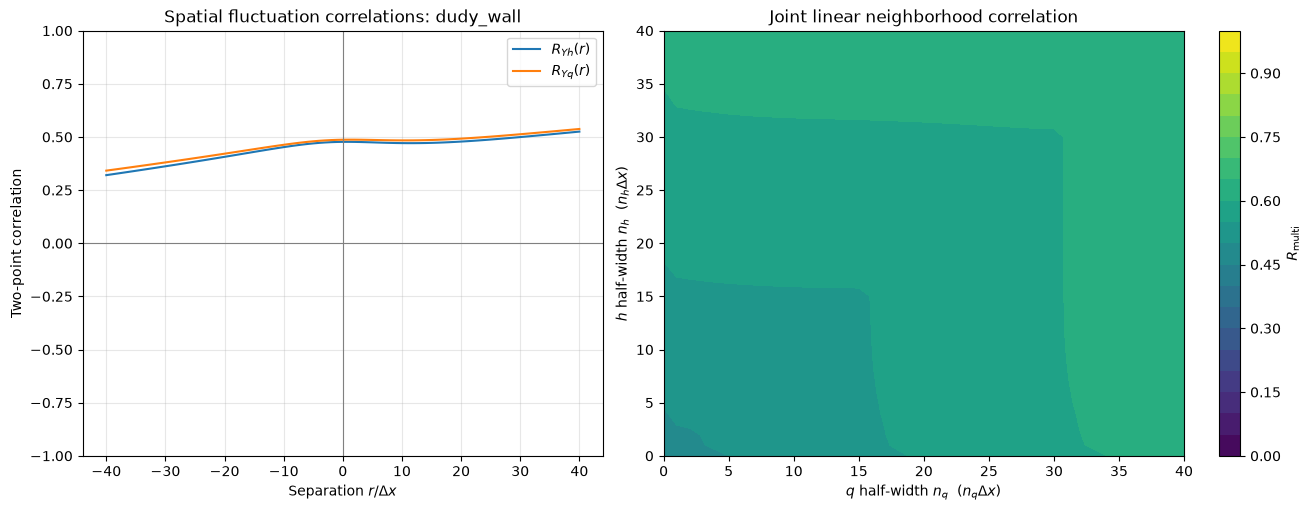

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5), constrained_layout=True
)

axes[0].plot(separations / dx, R_Yh, label=r"$R_{Yh}(r)$")
axes[0].plot(separations / dx, R_Yq, label=r"$R_{Yq}(r)$")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].axvline(0, color="gray", linewidth=0.8)
axes[0].set_ylim(-1, 1)
axes[0].set_xlabel(r"Separation $r/\Delta x$")
axes[0].set_ylabel("Two-point correlation")
axes[0].set_title(f"Spatial fluctuation correlations: {QOI}")
axes[0].legend()
axes[0].grid(alpha=0.3)

contour = axes[1].contourf(
    kq,
    kh,
    R_neighborhood,
    levels=np.linspace(0, 1, 21),
    cmap="viridis",
)

axes[1].set_xlabel(r"$q$ half-width $n_q$  ($n_q\Delta x$)")
axes[1].set_ylabel(r"$h$ half-width $n_h$  ($n_h\Delta x$)")
axes[1].set_title("Joint linear neighborhood correlation")
fig.colorbar(contour, ax=axes[1], label=r"$R_{\mathrm{multi}}$")

plt.show()

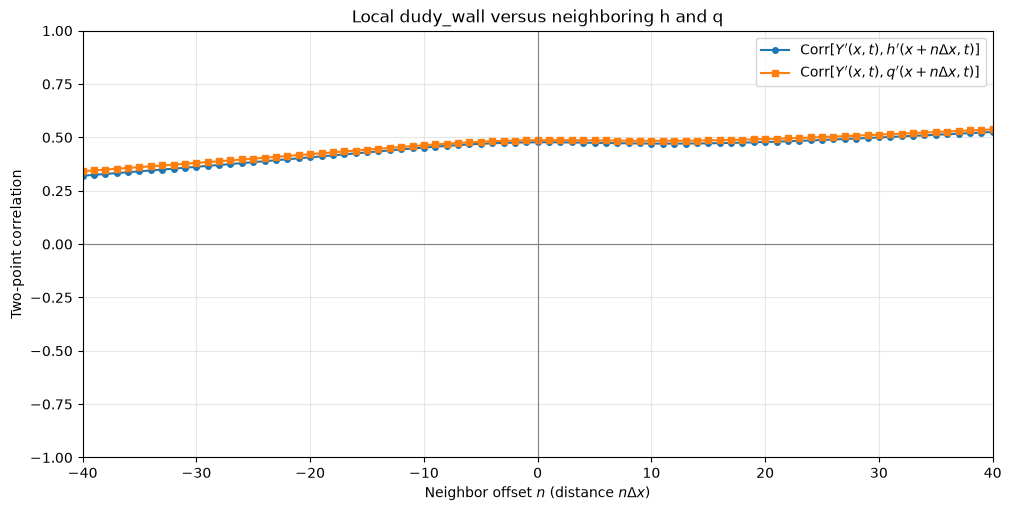

In [19]:
import matplotlib.pyplot as plt

n_offsets = np.rint(separations / dx).astype(int)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

ax.plot(
    n_offsets, R_Yh,
    "o-", markersize=4,
    label=r"$\mathrm{Corr}[Y'(x,t),h'(x+n\Delta x,t)]$",
)
ax.plot(
    n_offsets, R_Yq,
    "s-", markersize=4,
    label=r"$\mathrm{Corr}[Y'(x,t),q'(x+n\Delta x,t)]$",
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_ylim(-1, 1)
ax.set_xlim(n_offsets.min(), n_offsets.max())
ax.set_xlabel(r"Neighbor offset $n$ (distance $n\Delta x$)")
ax.set_ylabel("Two-point correlation")
ax.set_title(f"Local {QOI} versus neighboring h and q")
ax.legend()
ax.grid(alpha=0.3)
# ax.set_xlim(-5,5)
plt.show()

In [20]:
import h5py
import numpy as np

FILE_PATH = DATA_DIR / "thinfilm_closure_data_Re040_Ca0_100_theta45.h5"
QOI = "dudy_wall"

# H_HALF_WIDTHS = np.array([0.0, 0.05, 0.10, 0.20, 0.40, 0.80])
# Q_HALF_WIDTHS = np.array([0.0, 0.05, 0.10, 0.20, 0.40, 0.80])

BLOCK_SIZE_X = 128

with h5py.File(FILE_PATH, "r") as f:
    x = np.asarray(f["x"][:], dtype=float).reshape(-1)
    t = np.asarray(f["t"][:], dtype=float).reshape(-1)
    nx, nt = len(x), len(t)

    h = read_spatial_field(f, "h", nx, nt)
    q = read_spatial_field(f, "q", nx, nt)
    y = read_spatial_field(f, QOI, nx, nt)

dx = np.mean(np.diff(x))
H_HALF_WIDTHS = np.arange(41, dtype=float) * dx
Q_HALF_WIDTHS = np.arange(41, dtype=float) * dx

if dx <= 0 or not np.allclose(np.diff(x), dx):
    raise ValueError("This implementation requires an increasing uniform grid.")

if np.any(H_HALF_WIDTHS < 0) or np.any(Q_HALF_WIDTHS < 0):
    raise ValueError("Half-widths must be non-negative.")

# Reynolds-type fluctuations: subtract the time mean at each x.
def fluctuations(field):
    field = np.where(np.isfinite(field), field, np.nan)
    return field - np.nanmean(field, axis=1, keepdims=True)

hp = fluctuations(h)
qp = fluctuations(q)
yp = fluctuations(y)

# Include all grid points lying inside each requested physical half-width.
kh = np.floor(H_HALF_WIDTHS / dx + 1e-9).astype(int)
kq = np.floor(Q_HALF_WIDTHS / dx + 1e-9).astype(int)
K = int(max(kh.max(), kq.max()))

if 2 * K >= nx:
    raise ValueError("The largest neighborhood is wider than the domain.")

offsets = np.arange(-K, K + 1)
separations = offsets * dx
window_size = len(offsets)

# Columns: h' at each offset, q' at each offset, local Y'.
n_columns = 2 * window_size + 1
sum_values = np.zeros(n_columns)
sum_products = np.zeros((n_columns, n_columns))
n_pairs = 0

# Common centers ensure every width uses the same x,t observations.
for start in range(K, nx - K, BLOCK_SIZE_X):
    stop = min(start + BLOCK_SIZE_X, nx - K)

    columns = [
        hp[start + offset:stop + offset].reshape(-1)
        for offset in offsets
    ]
    columns += [
        qp[start + offset:stop + offset].reshape(-1)
        for offset in offsets
    ]
    columns.append(yp[start:stop].reshape(-1))

    block = np.column_stack(columns)
    block = block[np.all(np.isfinite(block), axis=1)]

    if len(block):
        sum_values += block.sum(axis=0)
        sum_products += block.T @ block
        n_pairs += len(block)

if n_pairs < 2:
    raise ValueError("Not enough finite observations.")

mean_values = sum_values / n_pairs
covariance = (
    sum_products / n_pairs
    - np.outer(mean_values, mean_values)
)
covariance = 0.5 * (covariance + covariance.T)

if covariance[-1, -1] <= 0:
    raise ValueError("The QoI has no fluctuation variance.")

print(f"QoI: {QOI}")
print(f"Grid spacing: {dx:.6g}")
print(f"Included x,t observations: {n_pairs:,}")
print("Actual h half-widths:", kh * dx)
print("Actual q half-widths:", kq * dx)

QoI: dudy_wall
Grid spacing: 0.0488281
Included x,t observations: 2,951,024
Actual h half-widths: [0.         0.04882812 0.09765625 0.14648438 0.1953125  0.24414062
 0.29296875 0.34179688 0.390625   0.43945312 0.48828125 0.53710938
 0.5859375  0.63476562 0.68359375 0.73242188 0.78125    0.83007812
 0.87890625 0.92773438 0.9765625  1.02539062 1.07421875 1.12304688
 1.171875   1.22070312 1.26953125 1.31835938 1.3671875  1.41601562
 1.46484375 1.51367188 1.5625     1.61132812 1.66015625 1.70898438
 1.7578125  1.80664062 1.85546875 1.90429688 1.953125  ]
Actual q half-widths: [0.         0.04882812 0.09765625 0.14648438 0.1953125  0.24414062
 0.29296875 0.34179688 0.390625   0.43945312 0.48828125 0.53710938
 0.5859375  0.63476562 0.68359375 0.73242188 0.78125    0.83007812
 0.87890625 0.92773438 0.9765625  1.02539062 1.07421875 1.12304688
 1.171875   1.22070312 1.26953125 1.31835938 1.3671875  1.41601562
 1.46484375 1.51367188 1.5625     1.61132812 1.66015625 1.70898438
 1.7578125  1.80664

Peaks: 19,956 selected x,t observations
Troughs: 952,558 selected x,t observations


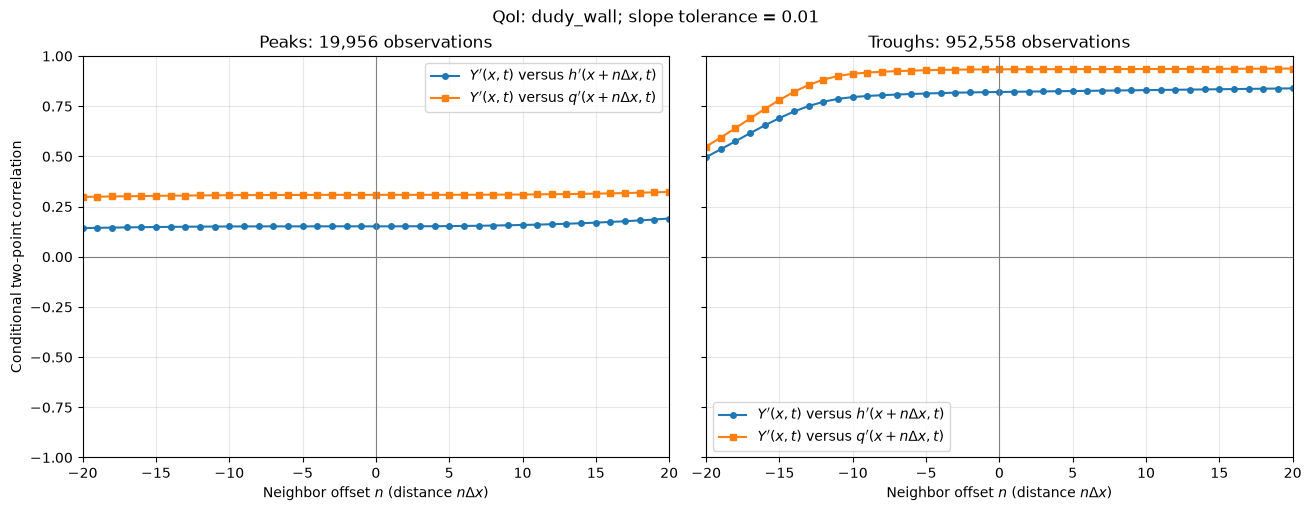

In [21]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

MAX_OFFSET = 20
HX_TOL = 0.01  # Approximate zero: |h_x| <= HX_TOL

with h5py.File(FILE_PATH, "r") as f:
    hx = read_spatial_field(f, "h_x", len(x), len(t))

nx, nt = h.shape
K = MAX_OFFSET
if 2 * K >= nx:
    raise ValueError("MAX_OFFSET is too large for the spatial domain.")

n_offsets = np.arange(-K, K + 1)
start, stop = K, nx - K

h_center = h[start:stop, :]
hx_center = hx[start:stop, :]
y_center = yp[start:stop, :]

# Same finite observations at every separation and for both fields.
common_valid = (
    np.isfinite(h_center)
    & np.isfinite(hx_center)
    & np.isfinite(y_center)
)

for n in n_offsets:
    common_valid &= (
        np.isfinite(hp[start + n:stop + n, :])
        & np.isfinite(qp[start + n:stop + n, :])
    )

conditions = {
    "Peaks": (
        common_valid
        & (h_center > 1.2)
        & (np.abs(hx_center) <= HX_TOL)
    ),
    "Troughs": (
        common_valid
        & (h_center < 0.8)
        & (np.abs(hx_center) <= HX_TOL)
    ),
}

def conditional_pearson(a, b):
    """Pearson correlation within the selected observations."""
    if a.size < 2:
        return np.nan

    # Selected fluctuations need not have zero conditional mean.
    ac = a - np.mean(a)
    bc = b - np.mean(b)

    denominator = np.sqrt(np.dot(ac, ac) * np.dot(bc, bc))
    if denominator <= 0:
        return np.nan

    return np.clip(np.dot(ac, bc) / denominator, -1.0, 1.0)

conditional_correlations = {}

for region, mask in conditions.items():
    y_selected = y_center[mask]
    Rh = np.full(len(n_offsets), np.nan)
    Rq = np.full(len(n_offsets), np.nan)

    for i, n in enumerate(n_offsets):
        h_neighbor = hp[start + n:stop + n, :][mask]
        q_neighbor = qp[start + n:stop + n, :][mask]

        Rh[i] = conditional_pearson(y_selected, h_neighbor)
        Rq[i] = conditional_pearson(y_selected, q_neighbor)

    conditional_correlations[region] = {
        "h": Rh,
        "q": Rq,
        "n_points": int(mask.sum()),
    }

    print(f"{region}: {mask.sum():,} selected x,t observations")

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, (region, result) in zip(
    axes, conditional_correlations.items()
):
    ax.plot(
        n_offsets, result["h"], "o-", markersize=4,
        label=r"$Y'(x,t)$ versus $h'(x+n\Delta x,t)$",
    )
    ax.plot(
        n_offsets, result["q"], "s-", markersize=4,
        label=r"$Y'(x,t)$ versus $q'(x+n\Delta x,t)$",
    )

    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_ylim(-1, 1)
    ax.set_xlim(-K, K)
    ax.set_xlabel(r"Neighbor offset $n$ (distance $n\Delta x$)")
    ax.set_title(f"{region}: {result['n_points']:,} observations")
    ax.legend(fontsize=10)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Conditional two-point correlation")
fig.suptitle(f"QoI: {QOI}; slope tolerance = {HX_TOL:g}")
plt.show()

dudy_wall, Peaks: 19,915 selected x,t observations
dudy_wall, Troughs: 952,509 selected x,t observations
int_u2_dy, Peaks: 19,915 selected x,t observations
int_u2_dy, Troughs: 952,509 selected x,t observations
u_interface, Peaks: 19,915 selected x,t observations
u_interface, Troughs: 952,509 selected x,t observations


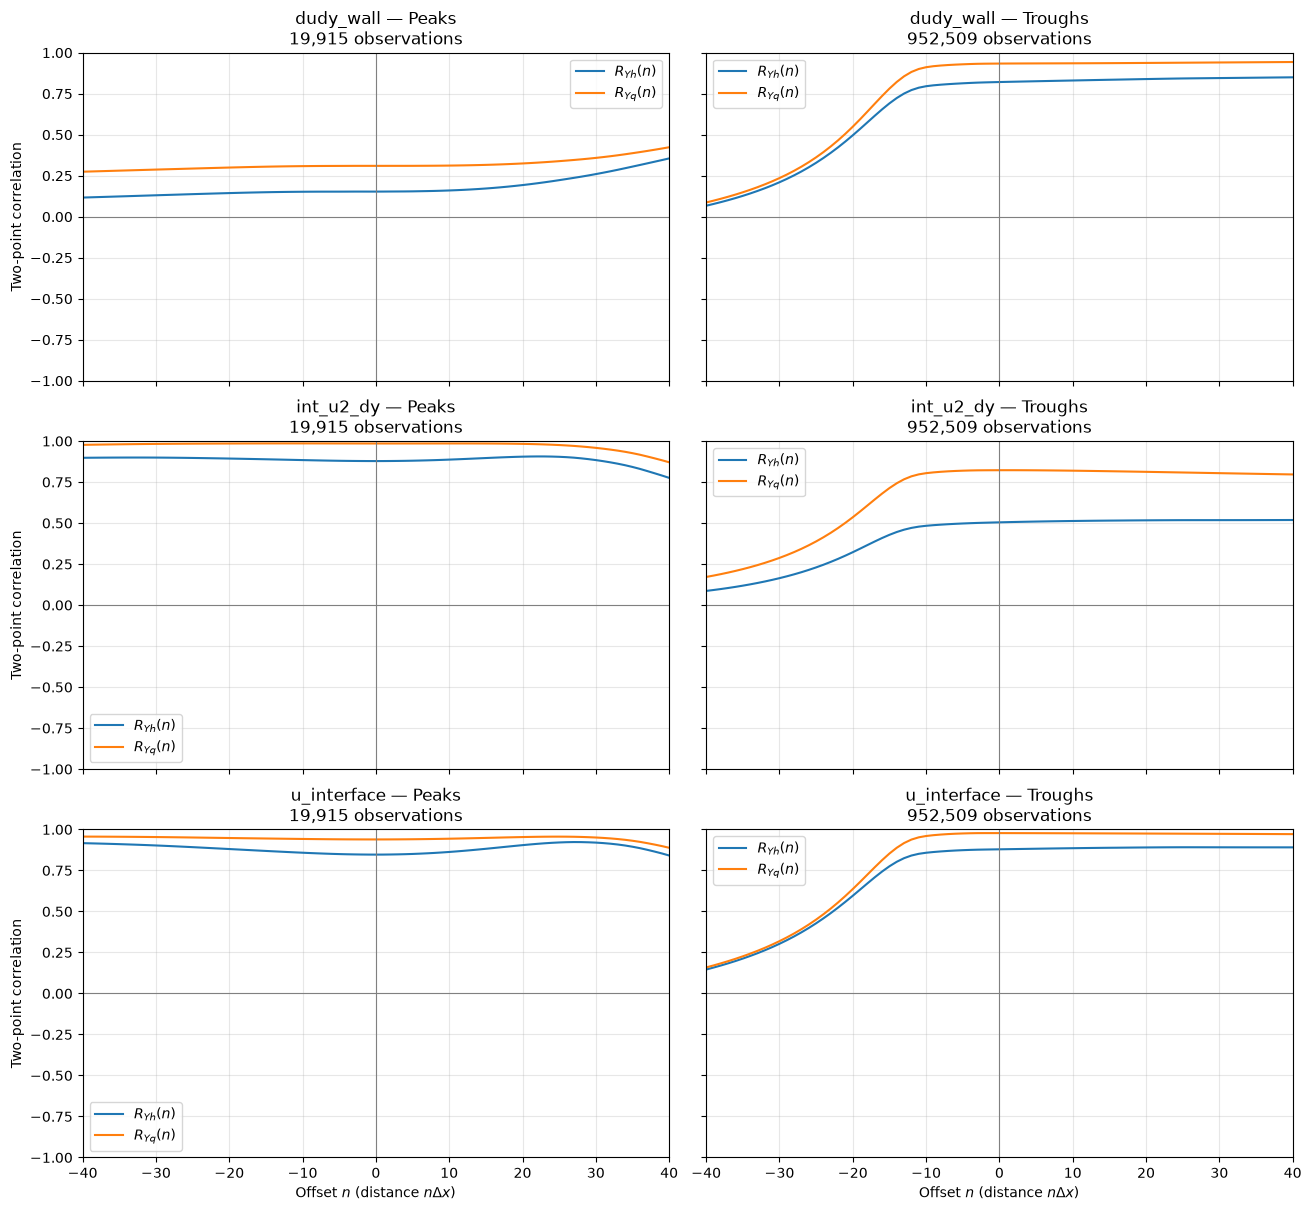

In [22]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

FILE_PATH = DATA_DIR / "thinfilm_closure_data_Re040_Ca0_100_theta45.h5"

QOIS = [
    "dudy_wall",
    "int_u2_dy",
    "u_interface",
]

MAX_OFFSET = 40
HX_TOL = 0.01

# Add "All" here to also plot the unconditional correlation.
REGIONS = ["Peaks", "Troughs"]


def fluctuations(field):
    """Subtract the time mean separately at each spatial location."""
    field = np.where(np.isfinite(field), field, np.nan)
    return field - np.nanmean(field, axis=1, keepdims=True)


def conditional_pearson(a, b):
    """Pearson correlation over the selected x,t observations."""
    if a.size < 2:
        return np.nan

    ac = a - np.mean(a)
    bc = b - np.mean(b)
    denominator = np.sqrt(np.dot(ac, ac) * np.dot(bc, bc))

    if denominator <= 0:
        return np.nan

    return np.clip(np.dot(ac, bc) / denominator, -1.0, 1.0)


with h5py.File(FILE_PATH, "r") as f:
    x = np.asarray(f["x"][:], dtype=float).reshape(-1)
    t = np.asarray(f["t"][:], dtype=float).reshape(-1)
    nx, nt = len(x), len(t)

    h = read_spatial_field(f, "h", nx, nt)
    q = read_spatial_field(f, "q", nx, nt)
    hx = read_spatial_field(f, "h_x", nx, nt)

dx = x[1] - x[0]

if dx <= 0 or not np.allclose(np.diff(x), dx):
    raise ValueError("Expected an increasing uniform spatial grid.")

K = MAX_OFFSET
if K < 0 or 2 * K >= nx:
    raise ValueError("Invalid MAX_OFFSET.")

n_offsets = np.arange(-K, K + 1)
start, stop = K, nx - K

hp = fluctuations(h)
qp = fluctuations(q)

h_center = h[start:stop, :]
hx_center = hx[start:stop, :]

# Require complete finite h,q neighborhoods.
# This makes every separation use the same observations.
base_valid = np.isfinite(h_center)

for n in n_offsets:
    base_valid &= (
        np.isfinite(hp[start + n:stop + n, :])
        & np.isfinite(qp[start + n:stop + n, :])
    )

region_masks = {
    "All": base_valid,
    "Peaks": (
        base_valid
        & np.isfinite(hx_center)
        & (h_center > 1.2)
        & (np.abs(hx_center) <= HX_TOL)
    ),
    "Troughs": (
        base_valid
        & np.isfinite(hx_center)
        & (h_center < 0.8)
        & (np.abs(hx_center) <= HX_TOL)
    ),
}

correlation_results = {}

# Load one QoI at a time to limit memory usage.
with h5py.File(FILE_PATH, "r") as f:
    for name in QOIS:
        y = read_spatial_field(f, name, nx, nt)
        yp = fluctuations(y)
        y_center = yp[start:stop, :]

        correlation_results[name] = {}

        for region in REGIONS:
            mask = region_masks[region] & np.isfinite(y_center)
            y_selected = y_center[mask]

            Rh = np.full(len(n_offsets), np.nan)
            Rq = np.full(len(n_offsets), np.nan)

            for i, n in enumerate(n_offsets):
                h_selected = hp[start + n:stop + n, :][mask]
                q_selected = qp[start + n:stop + n, :][mask]

                Rh[i] = conditional_pearson(y_selected, h_selected)
                Rq[i] = conditional_pearson(y_selected, q_selected)

            correlation_results[name][region] = {
                "h": Rh,
                "q": Rq,
                "n_points": int(mask.sum()),
            }

            print(
                f"{name}, {region}: "
                f"{mask.sum():,} selected x,t observations"
            )

        del y, yp, y_center

# One row per QoI; one column per selected region.
fig, axes = plt.subplots(
    len(QOIS),
    len(REGIONS),
    figsize=(6.5 * len(REGIONS), 4 * len(QOIS)),
    sharex=True,
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)

for row, name in enumerate(QOIS):
    for col, region in enumerate(REGIONS):
        ax = axes[row, col]
        result = correlation_results[name][region]

        ax.plot(
            n_offsets, result["h"],
            color="tab:blue", linewidth=1.5,
            label=r"$R_{Yh}(n)$",
        )
        ax.plot(
            n_offsets, result["q"],
            color="tab:orange", linewidth=1.5,
            label=r"$R_{Yq}(n)$",
        )

        ax.axhline(0, color="gray", linewidth=0.8)
        ax.axvline(0, color="gray", linewidth=0.8)
        ax.set_ylim(-1, 1)
        ax.set_xlim(-K, K)
        ax.set_title(
            f"{name} — {region}\n"
            f"{result['n_points']:,} observations"
        )
        ax.grid(alpha=0.3)
        ax.legend()

        if col == 0:
            ax.set_ylabel("Two-point correlation")
        if row == len(QOIS) - 1:
            ax.set_xlabel(r"Offset $n$ (distance $n\Delta x$)")

plt.show()

delta_Dx_ML, Peaks: 19,915 selected x,t observations
delta_Dx_ML, Troughs: 952,509 selected x,t observations
delta_M_ML, Peaks: 19,915 selected x,t observations
delta_M_ML, Troughs: 952,509 selected x,t observations
delta_Px_ML, Peaks: 19,915 selected x,t observations
delta_Px_ML, Troughs: 952,509 selected x,t observations
delta_Tw_ML, Peaks: 19,915 selected x,t observations
delta_Tw_ML, Troughs: 952,509 selected x,t observations


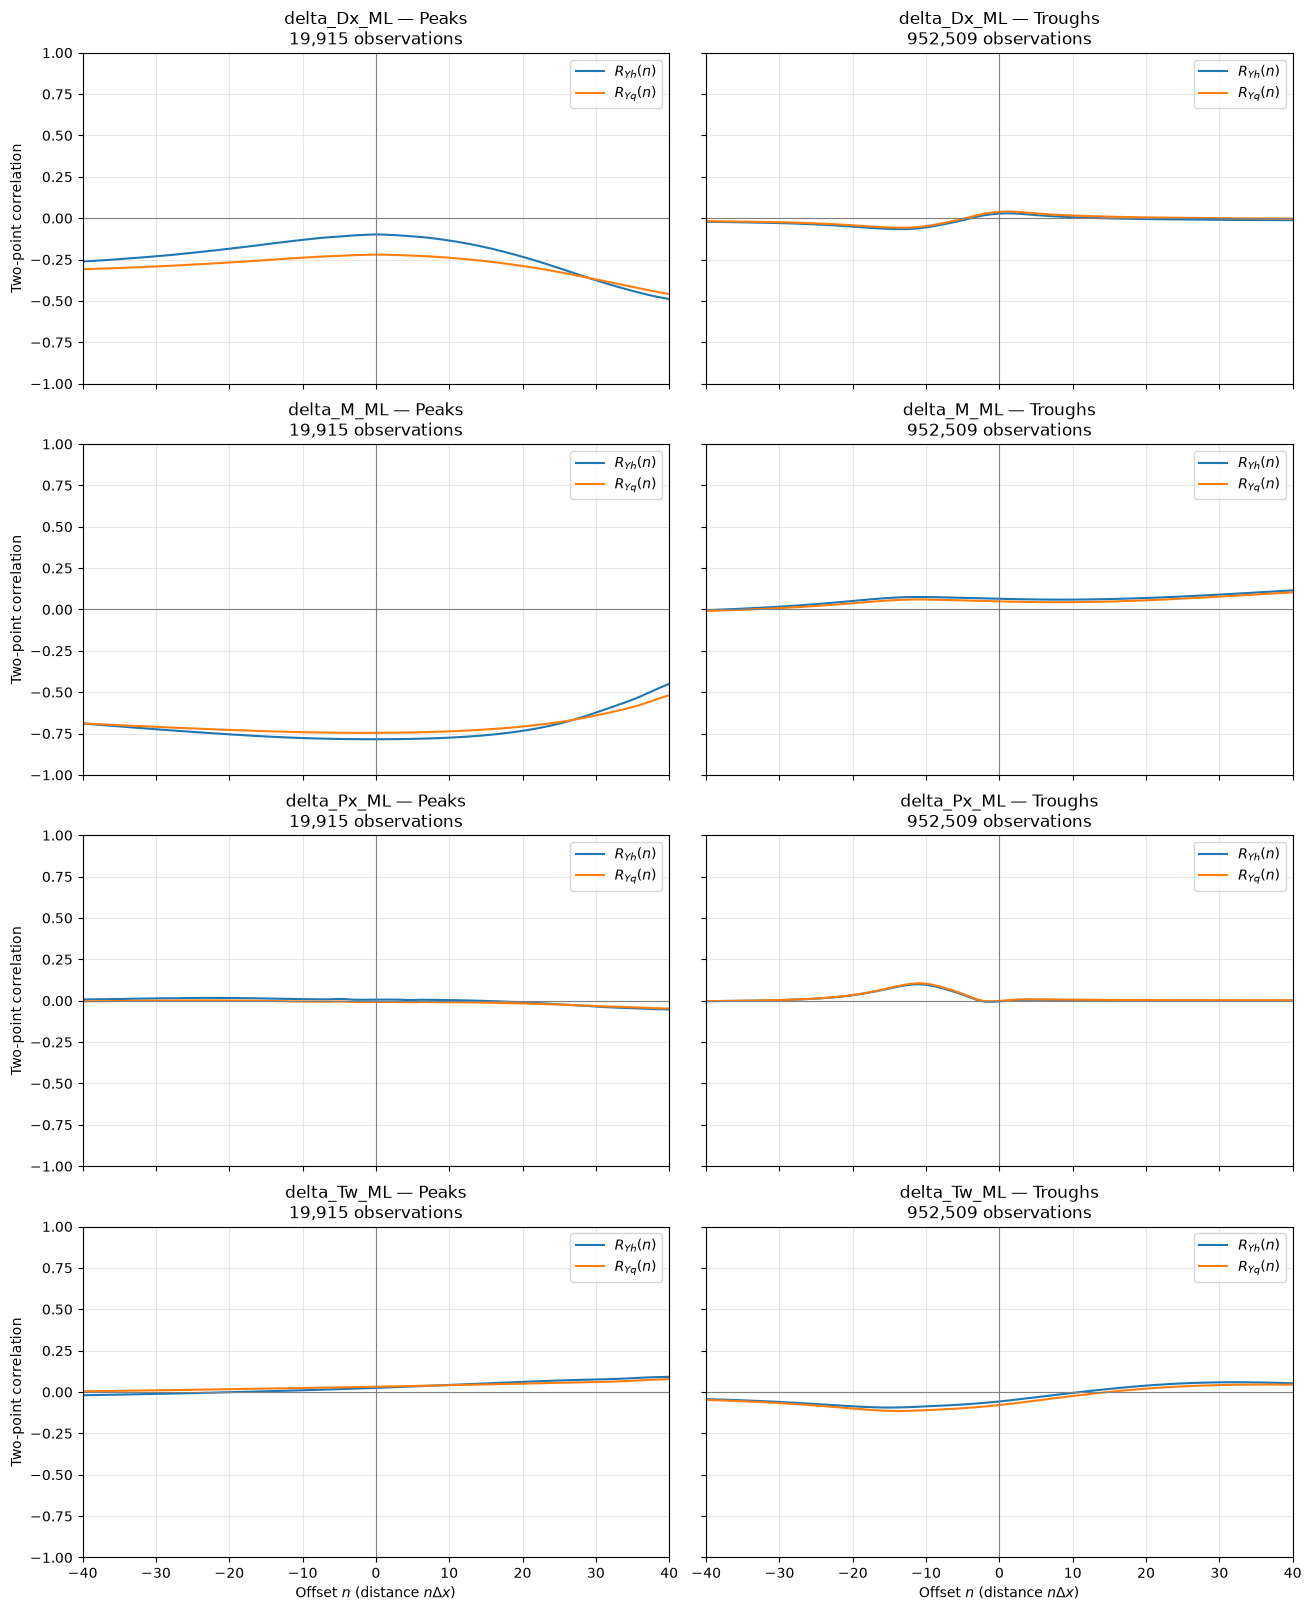

In [23]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

FILE_PATH = DATA_DIR / "thinfilm_closure_data_Re040_Ca0_100_theta45.h5"

QOIS = [
    "delta_Dx_ML",
    "delta_M_ML",
    "delta_Px_ML",
    "delta_Tw_ML"
]

MAX_OFFSET = 40
HX_TOL = 0.01

# Add "All" here to also plot the unconditional correlation.
REGIONS = ["Peaks", "Troughs"]


def fluctuations(field):
    """Subtract the time mean separately at each spatial location."""
    field = np.where(np.isfinite(field), field, np.nan)
    return field - np.nanmean(field, axis=1, keepdims=True)


def conditional_pearson(a, b):
    """Pearson correlation over the selected x,t observations."""
    if a.size < 2:
        return np.nan

    ac = a - np.mean(a)
    bc = b - np.mean(b)
    denominator = np.sqrt(np.dot(ac, ac) * np.dot(bc, bc))

    if denominator <= 0:
        return np.nan

    return np.clip(np.dot(ac, bc) / denominator, -1.0, 1.0)


with h5py.File(FILE_PATH, "r") as f:
    x = np.asarray(f["x"][:], dtype=float).reshape(-1)
    t = np.asarray(f["t"][:], dtype=float).reshape(-1)
    nx, nt = len(x), len(t)

    h = read_spatial_field(f, "h", nx, nt)
    q = read_spatial_field(f, "q", nx, nt)
    hx = read_spatial_field(f, "h_x", nx, nt)

dx = x[1] - x[0]

if dx <= 0 or not np.allclose(np.diff(x), dx):
    raise ValueError("Expected an increasing uniform spatial grid.")

K = MAX_OFFSET
if K < 0 or 2 * K >= nx:
    raise ValueError("Invalid MAX_OFFSET.")

n_offsets = np.arange(-K, K + 1)
start, stop = K, nx - K

hp = fluctuations(h)
qp = fluctuations(q)

h_center = h[start:stop, :]
hx_center = hx[start:stop, :]

# Require complete finite h,q neighborhoods.
# This makes every separation use the same observations.
base_valid = np.isfinite(h_center)

for n in n_offsets:
    base_valid &= (
        np.isfinite(hp[start + n:stop + n, :])
        & np.isfinite(qp[start + n:stop + n, :])
    )

region_masks = {
    "All": base_valid,
    "Peaks": (
        base_valid
        & np.isfinite(hx_center)
        & (h_center > 1.2)
        & (np.abs(hx_center) <= HX_TOL)
    ),
    "Troughs": (
        base_valid
        & np.isfinite(hx_center)
        & (h_center < 0.8)
        & (np.abs(hx_center) <= HX_TOL)
    ),
}

correlation_results = {}

# Load one QoI at a time to limit memory usage.
with h5py.File(FILE_PATH, "r") as f:
    for name in QOIS:
        y = read_spatial_field(f, name, nx, nt)
        yp = fluctuations(y)
        y_center = yp[start:stop, :]

        correlation_results[name] = {}

        for region in REGIONS:
            mask = region_masks[region] & np.isfinite(y_center)
            y_selected = y_center[mask]

            Rh = np.full(len(n_offsets), np.nan)
            Rq = np.full(len(n_offsets), np.nan)

            for i, n in enumerate(n_offsets):
                h_selected = hp[start + n:stop + n, :][mask]
                q_selected = qp[start + n:stop + n, :][mask]

                Rh[i] = conditional_pearson(y_selected, h_selected)
                Rq[i] = conditional_pearson(y_selected, q_selected)

            correlation_results[name][region] = {
                "h": Rh,
                "q": Rq,
                "n_points": int(mask.sum()),
            }

            print(
                f"{name}, {region}: "
                f"{mask.sum():,} selected x,t observations"
            )

        del y, yp, y_center

# One row per QoI; one column per selected region.
fig, axes = plt.subplots(
    len(QOIS),
    len(REGIONS),
    figsize=(6.5 * len(REGIONS), 4 * len(QOIS)),
    sharex=True,
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)

for row, name in enumerate(QOIS):
    for col, region in enumerate(REGIONS):
        ax = axes[row, col]
        result = correlation_results[name][region]

        ax.plot(
            n_offsets, result["h"],
            color="tab:blue", linewidth=1.5,
            label=r"$R_{Yh}(n)$",
        )
        ax.plot(
            n_offsets, result["q"],
            color="tab:orange", linewidth=1.5,
            label=r"$R_{Yq}(n)$",
        )

        ax.axhline(0, color="gray", linewidth=0.8)
        ax.axvline(0, color="gray", linewidth=0.8)
        ax.set_ylim(-1, 1)
        ax.set_xlim(-K, K)
        ax.set_title(
            f"{name} — {region}\n"
            f"{result['n_points']:,} observations"
        )
        ax.grid(alpha=0.3)
        ax.legend()

        if col == 0:
            ax.set_ylabel("Two-point correlation")
        if row == len(QOIS) - 1:
            ax.set_xlabel(r"Offset $n$ (distance $n\Delta x$)")

plt.show()